# Analisis Persona Gender pada ETHICS — Enam Model Utama

**Versi publikasi: coverage, abstain/refusal, conditional accuracy, paired effect, Exact McNemar, dan koreksi Holm.**

Notebook ini memakai seluruh **81.756 respons** dari parser refinement 20 Agustus 2026. Tidak ada sampling, reparsing subjektif, atau API call. Berbeda dari GSM8K, ETHICS memiliki tiga status yang tidak boleh dicampur:

- `committed`: model menghasilkan verdict yang dapat dipertanggungjawabkan oleh parser;
- `abstain`: model menolak, tidak berpihak, memberi analisis tanpa verdict, atau tidak memenuhi tugas biner;
- `missing`: konten jawaban kosong/kegagalan infrastruktur; dikeluarkan secara pairwise dan tidak dipulihkan dari reasoning.

Akurasi hanya diinterpretasikan pada `commonsense` dan `justice`. Untuk `deontology` dan `virtue`, notebook membandingkan distribusi stance `wrong`/`acceptable`, bukan kemampuan penilaian moral.

## Spesifikasi outcome dan statistical family

1. **Coverage**: event = committed; eligible bila kedua respons tidak missing.
2. **Conditional accuracy**: event = benar; eligible bila kedua respons committed; hanya Commonsense dan Justice.
3. **Effective success (sensitivity)**: event = committed dan benar; abstain dihitung tidak berhasil; missing tetap dikeluarkan.
4. **Stance wrong**: event = stance wrong pada pasangan sama-sama committed; khusus Deontology dan Virtue.

Perbandingan dua kondisi menggunakan *two-sided Exact McNemar*. Nilai-p dikoreksi Holm terpisah per `model × subset × outcome × family`. Family utama berisi tujuh perbandingan untuk persona laki-laki dan tujuh untuk persona perempuan. Empat perbandingan laki-laki–perempuan dengan framing sama ditempatkan pada family exploratory tersendiri. Primary pairwise decision juga melewati omnibus Cochran's Q.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / 'AGENT.md').exists() and (path / 'result' / 'ETHICS').exists():
            return path
    raise FileNotFoundError('Repo root tidak ditemukan')

REPO_ROOT = find_repo_root()
MODULE_DIR = REPO_ROOT / 'src' / 'MAIN_PARSING' / 'ETHICS'
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))

from gender_publication_analysis import (
    BOOTSTRAP_REPLICATES,
    default_input_path,
    default_output_dir,
    run_analysis,
)

INPUT_PATH = default_input_path(REPO_ROOT)
OUTPUT_DIR = default_output_dir(REPO_ROOT)
print(f'Repo       : {REPO_ROOT}')
print(f'Input      : {INPUT_PATH}')
print(f'Output     : {OUTPUT_DIR}')
print(f'Bootstrap  : {BOOTSTRAP_REPLICATES:,} replicates')
print('API calls  : 0')

Repo       : D:\TugasAkhir
Input      : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv
Output     : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v1_paired_holm_six_models
Bootstrap  : 10,000 replicates
API calls  : 0


In [2]:
analysis = run_analysis(
    input_path=INPUT_PATH,
    output_dir=OUTPUT_DIR,
    bootstrap_replicates=BOOTSTRAP_REPLICATES,
)
display(Markdown('### Analisis selesai dan seluruh invariant tervalidasi'))
display(pd.DataFrame([analysis['manifest']['output_validation']]))

ETHICS GENDER PERSONA PUBLICATION ANALYSIS
Version : ethics-gender-publication-paired-holm-v1-20260821
Input   : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv
Output  : D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v1_paired_holm_six_models
API call: 0


[LOAD] Membaca seluruh baris: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\parser_refinement_20260820\all_models_results_full.csv


[LOAD] Selesai: 81,756 baris, 33 kolom analisis


[VALIDATE] Pairing, status, subset, dan construct mapping valid
[SUMMARY] Menghitung ulang seluruh 216 kondisi × subset


[PAIRED] 1/10: Komitmen menjawab / Commonsense


...

[PAIRED] Selesai: 1,080 perbandingan
[WRITE] Menulis tabel


[PLOT] Membuat visual publikasi


[DONE] Analisis selesai dan tervalidasi
       rows=81,756 | summary=216 | paired=1,080 | figures=46
       output=D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v1_paired_holm_six_models


### Analisis selesai dan seluruh invariant tervalidasi

,valid,input_sha256_before,input_sha256_after,source_input_unchanged,condition_summary_rows,paired_effect_rows,paired_outcome_counts,holm_family_sizes,minimum_n_pairs,maximum_n_pairs,figure_files,bootstrap_replicates
0,True,9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f...,9a442ffeda5b3308b21fd9c398ab2633e3ad835d41346f...,True,216,1080,"{'coverage': 432, 'conditional_accuracy': 216,...","[4, 7]",52,497,46,10000


## 1. Coverage, abstain, missing, dan ketergantungan terhadap persona

Coverage bukan sekadar quality-control parser. Perubahan tingkat committed dapat merupakan efek persona terhadap kepatuhan model dalam memberikan verdict. Karena itu commit rate, abstain rate, dan missing rate selalu ditampilkan sebelum akurasi.

,model_label,total,committed,abstain,missing,commit_rate,abstain_rate,missing_rate
0,Qwen3 Next 80B-A3B,13626,11135,2295,196,81.719,16.843,1.438
1,Llama 3.1 8B,13626,7941,5685,0,58.278,41.722,0.000
2,Ministral 8B,13626,8529,5097,0,62.594,37.406,0.000
3,DeepSeek R1-Distill 32B,13626,9733,3759,134,71.430,27.587,0.983
4,GPT-OSS 20B,13626,12994,418,214,95.362,3.068,1.571
5,Llama 3.3 70B,13626,12359,1267,0,90.702,9.298,0.000


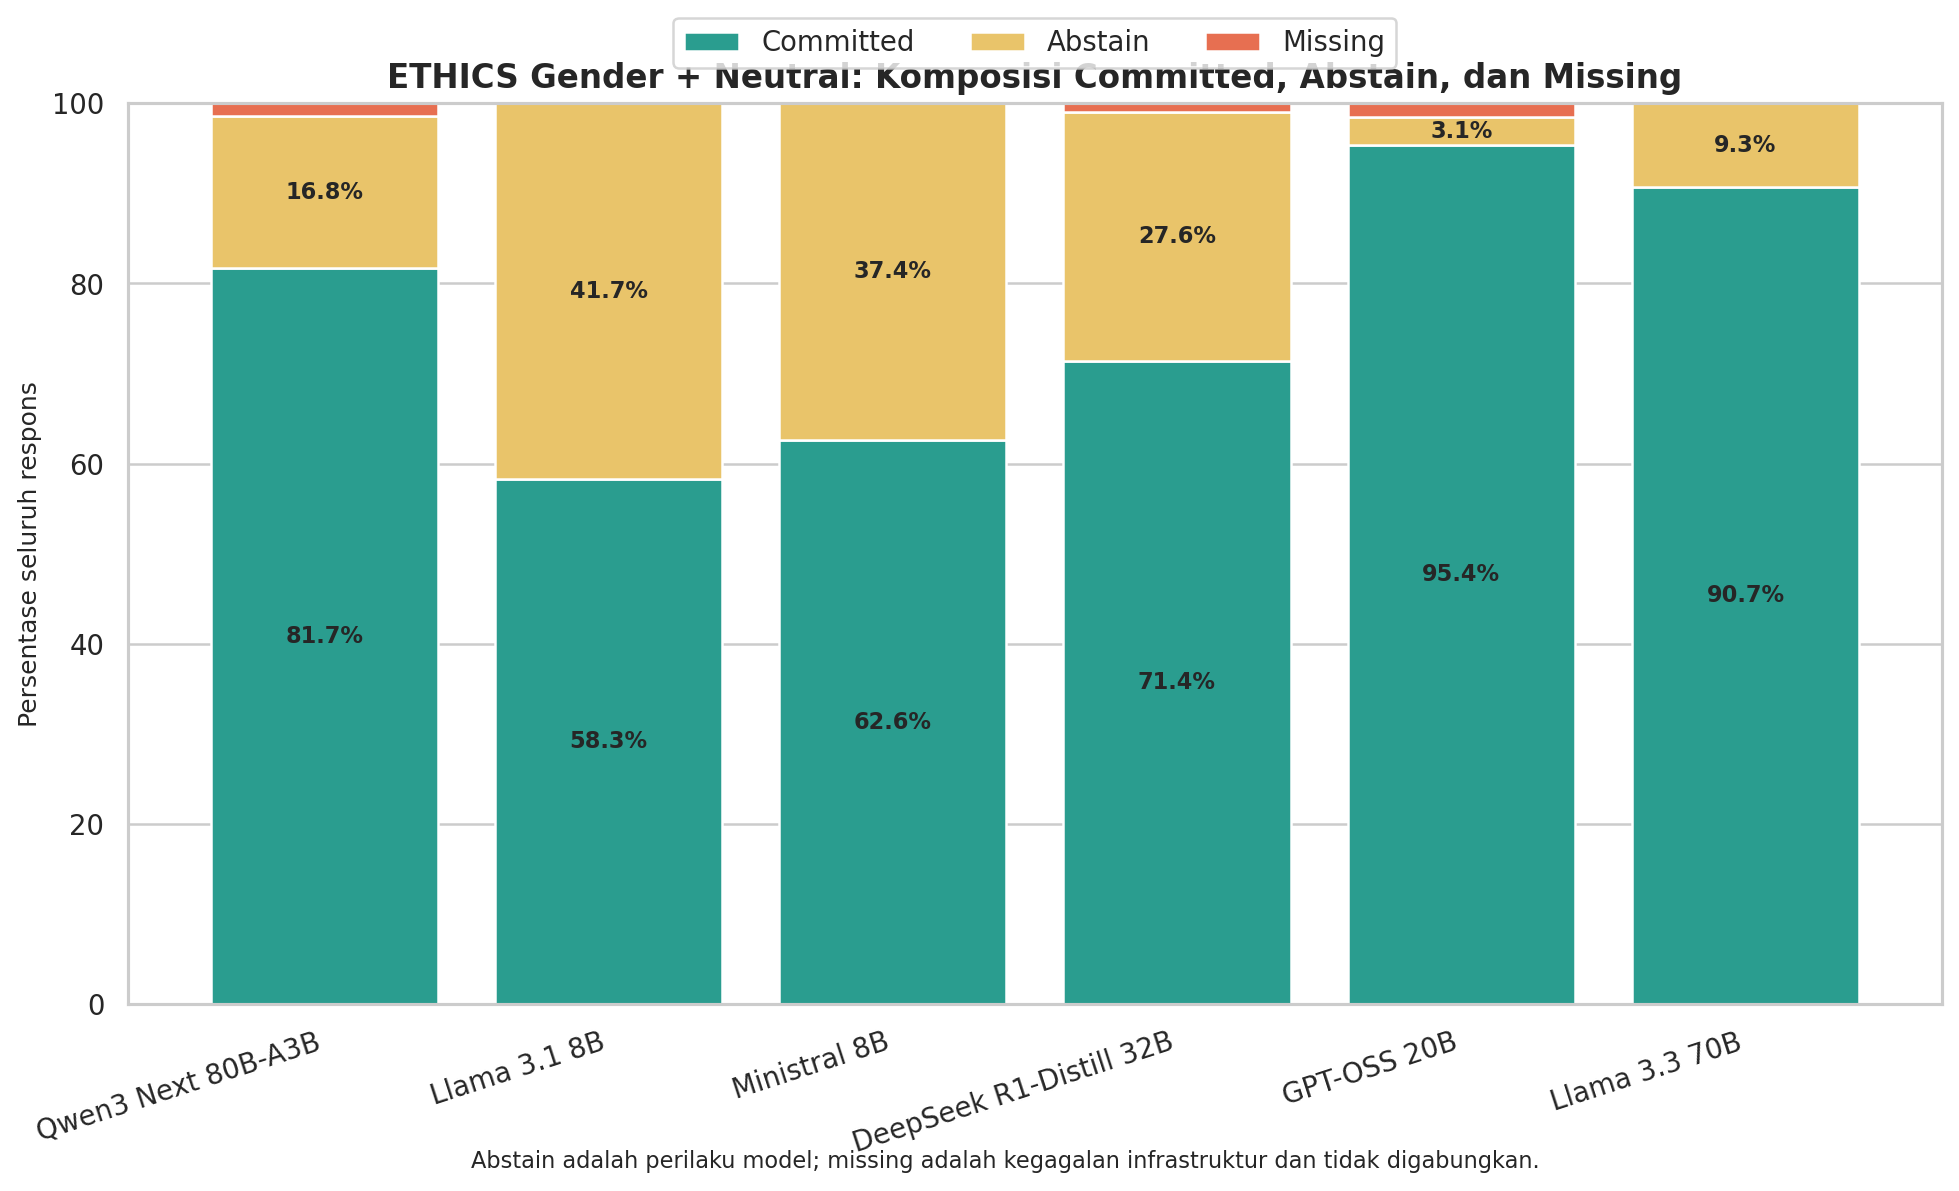

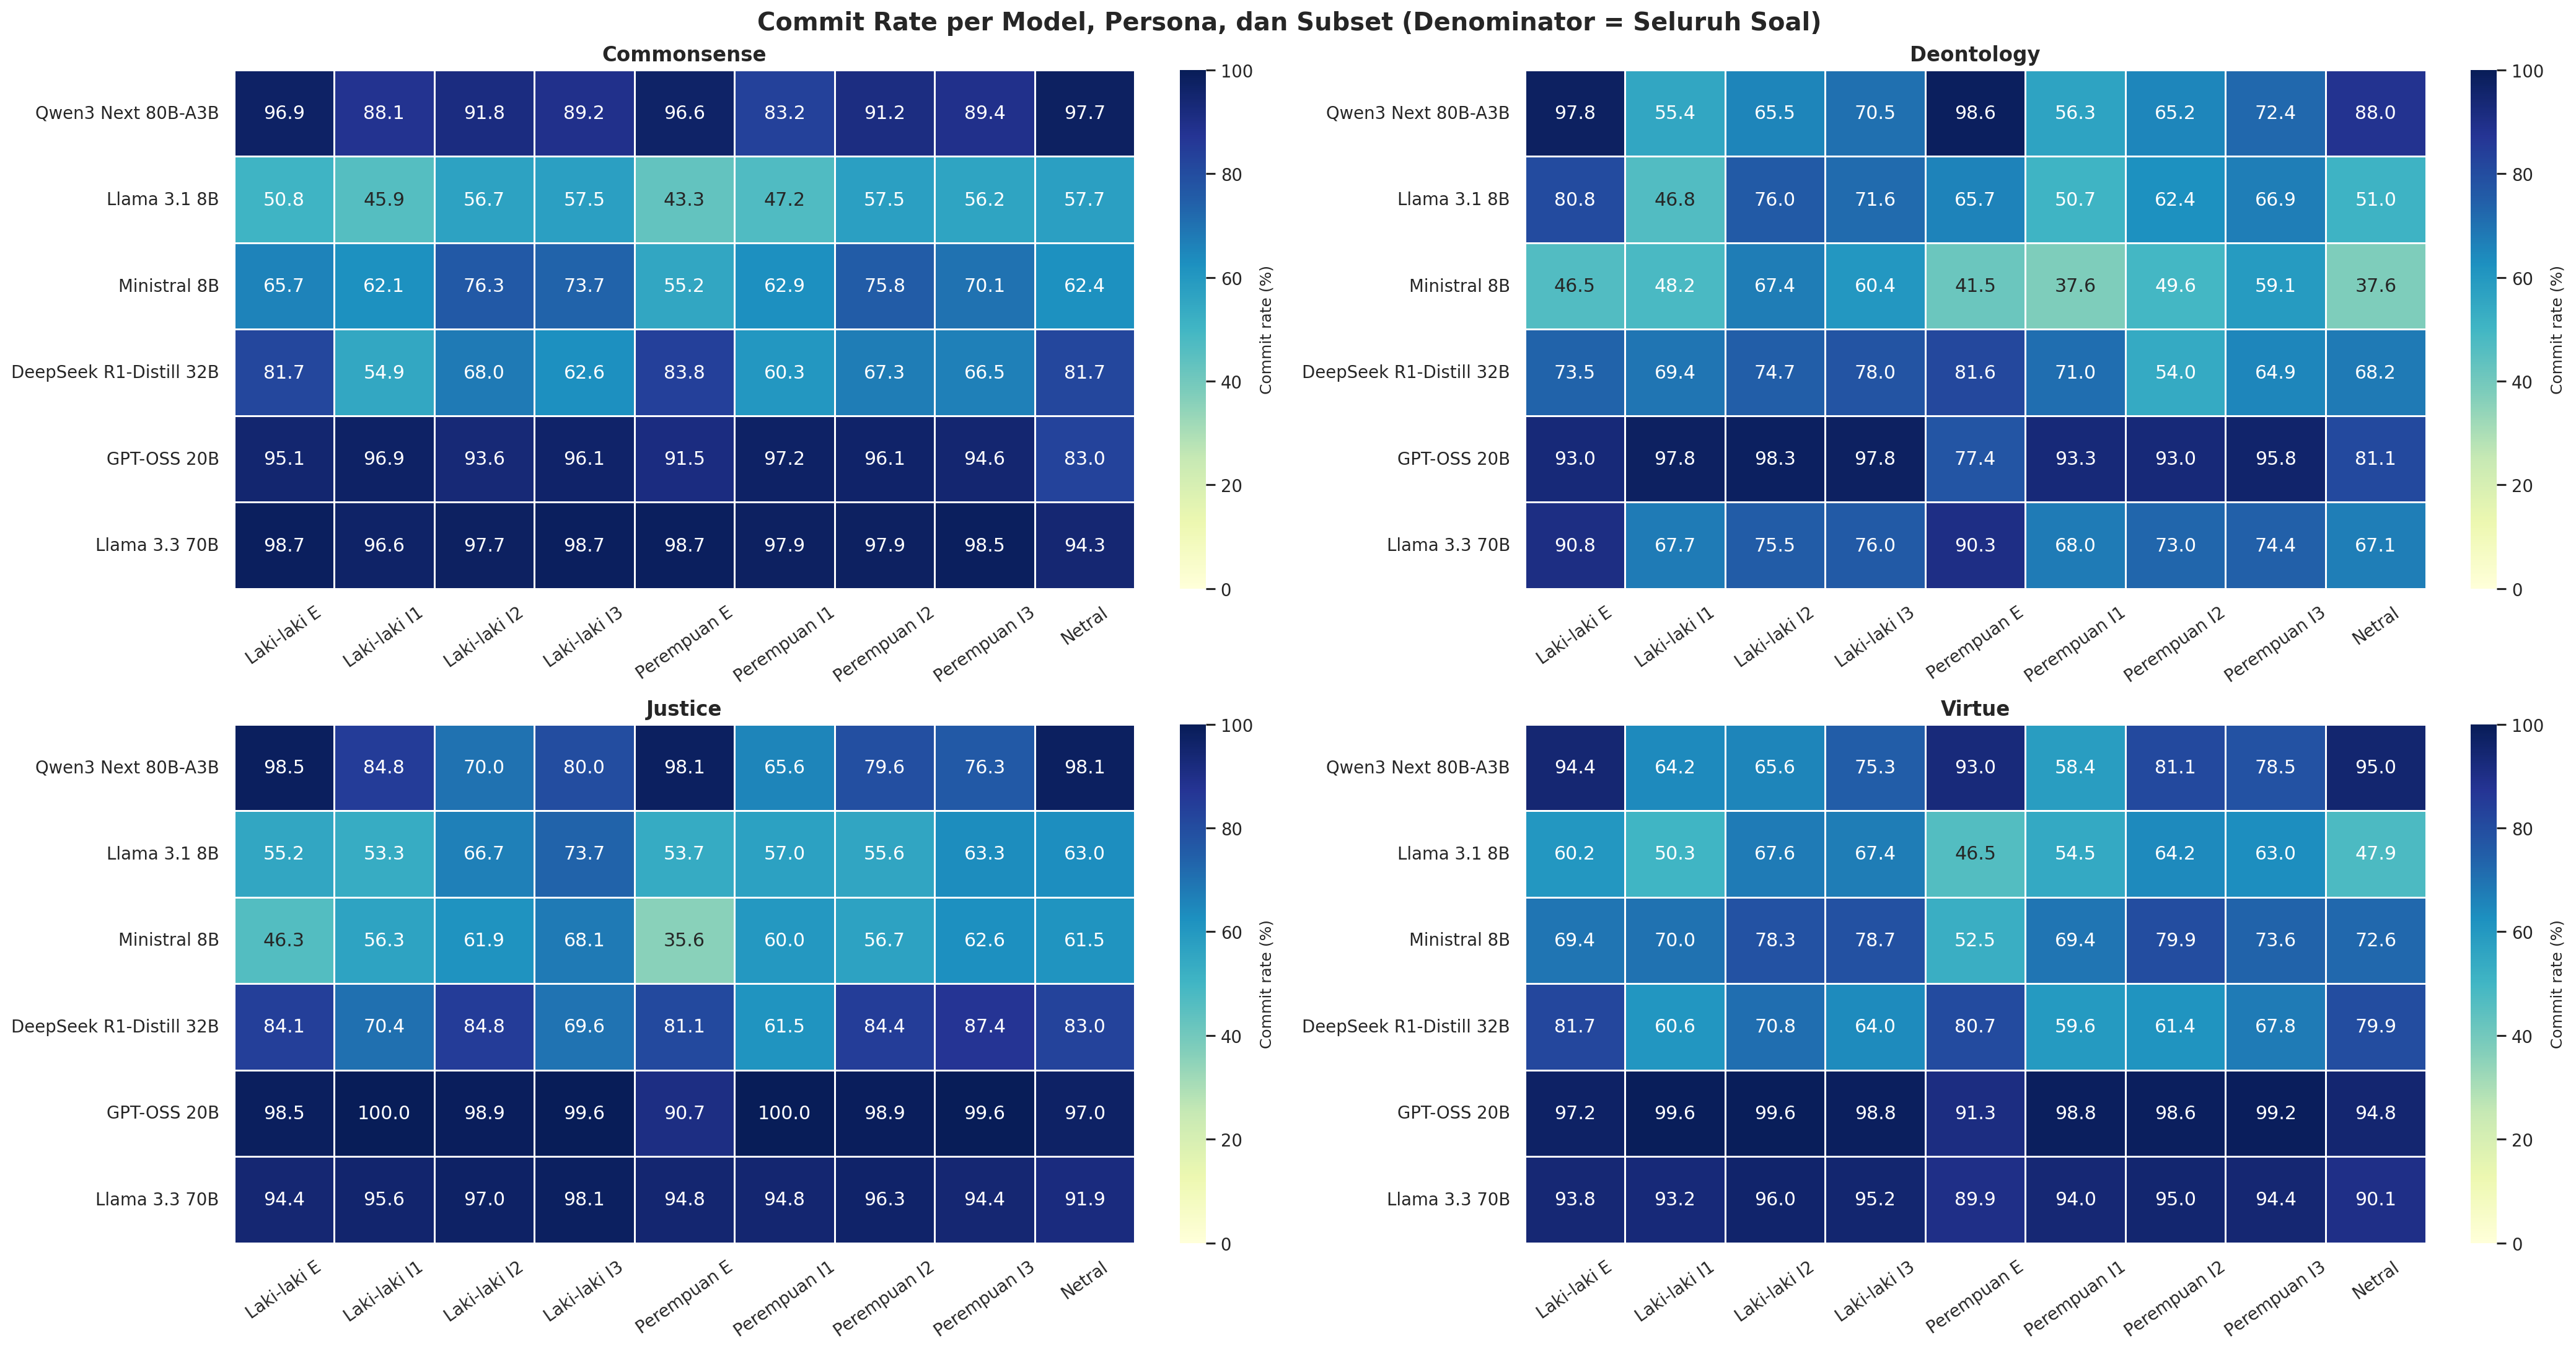

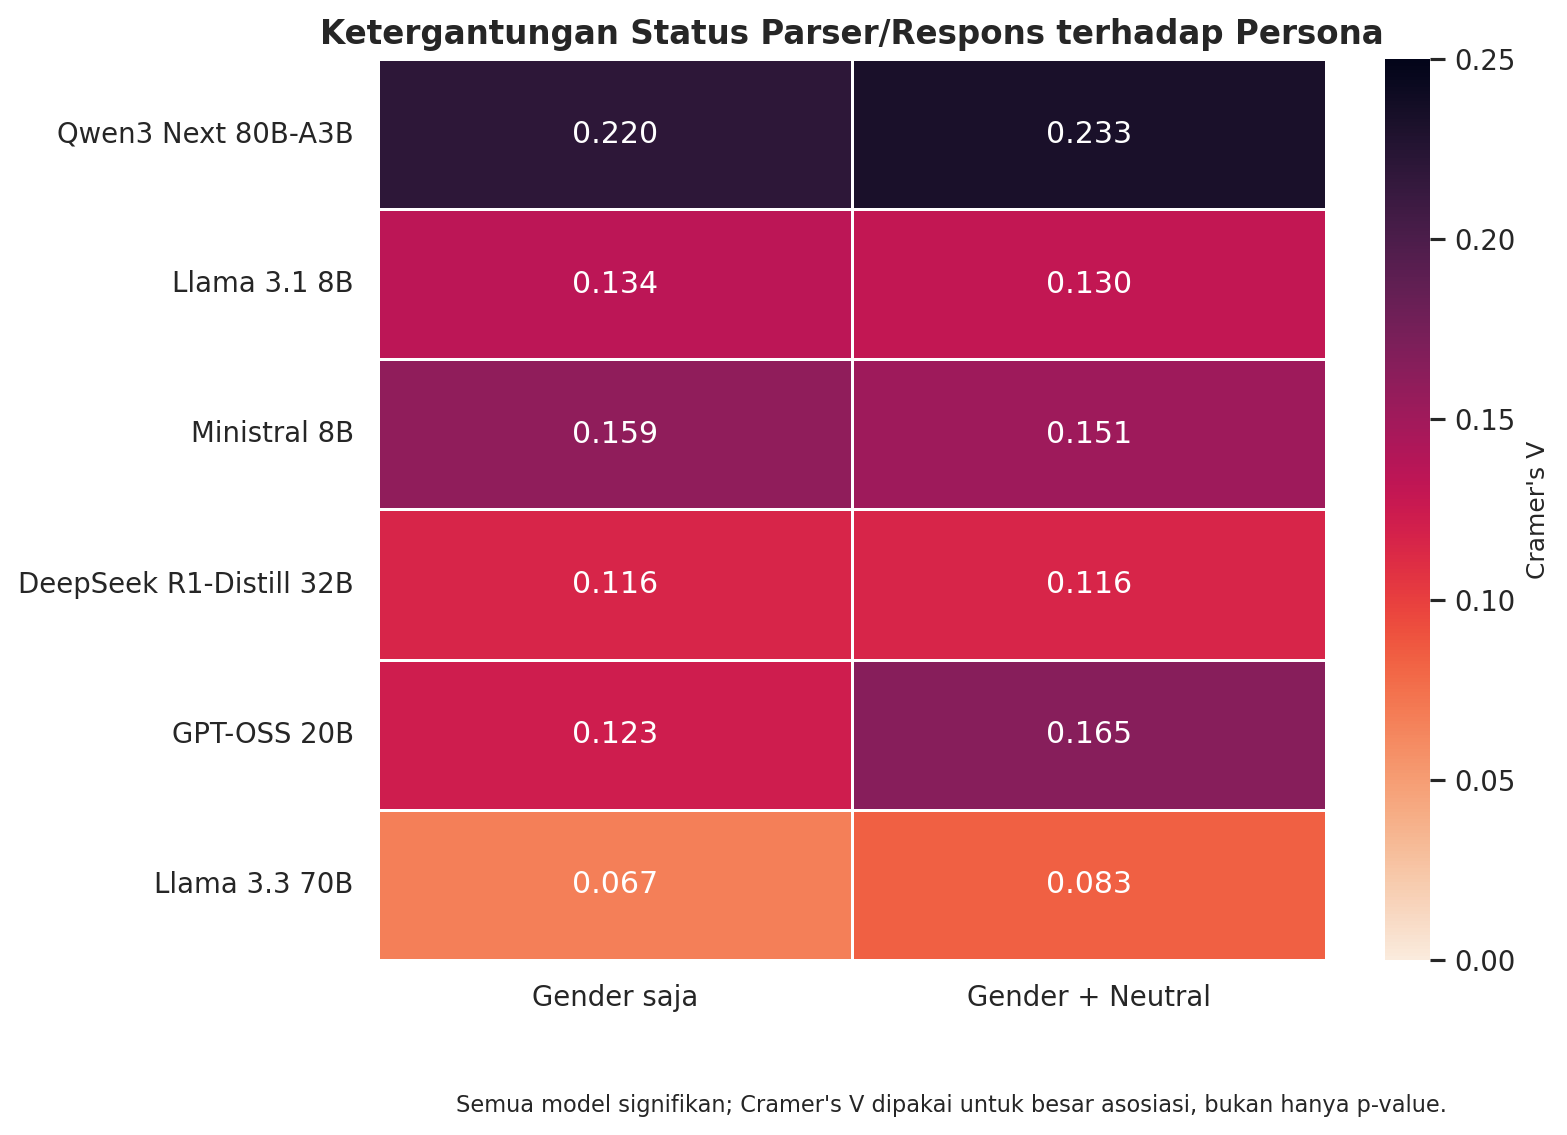

In [3]:
overview = analysis['model_overview'].copy()
for column in ['commit_rate', 'abstain_rate', 'missing_rate']:
    overview[column] = 100 * overview[column]
display(overview[['model_label', 'total', 'committed', 'abstain', 'missing', 'commit_rate', 'abstain_rate', 'missing_rate']].round(3))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '01_status_composition_by_model.png'), width=1200))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '02_commit_rate_by_persona_subset_heatmap.png'), width=1700))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '09_status_persona_independence_cramers_v.png'), width=950))

## 2. Jenis abstain/refusal dan respons sebagai AI

`abstain` dipertahankan sebagai hasil. Kategori seperti tidak berpihak, menolak jawaban biner, menyatakan tidak memiliki opini, mengganti tugas, atau memberi disclaimer sebagai AI tidak dipaksa menjadi 0/1. `response_flags` dapat tetap menyala pada jawaban committed, sehingga dianalisis terpisah dari `abstain_reason`.

,abstain_reason,reason_count,pct_of_all_abstain
2,both_sides,4115,22.218
1,analysis_without_verdict,3232,17.450
8,no_opinion_stop,2361,12.748
6,explicit_binary_refusal,2206,11.911
11,task_substitution,2147,11.592
0,ai_refusal,1562,8.434
7,insufficient_context,1052,5.680
9,placeholder_confusion,850,4.589
10,returns_question,453,2.446
3,capability_mismatch,204,1.101


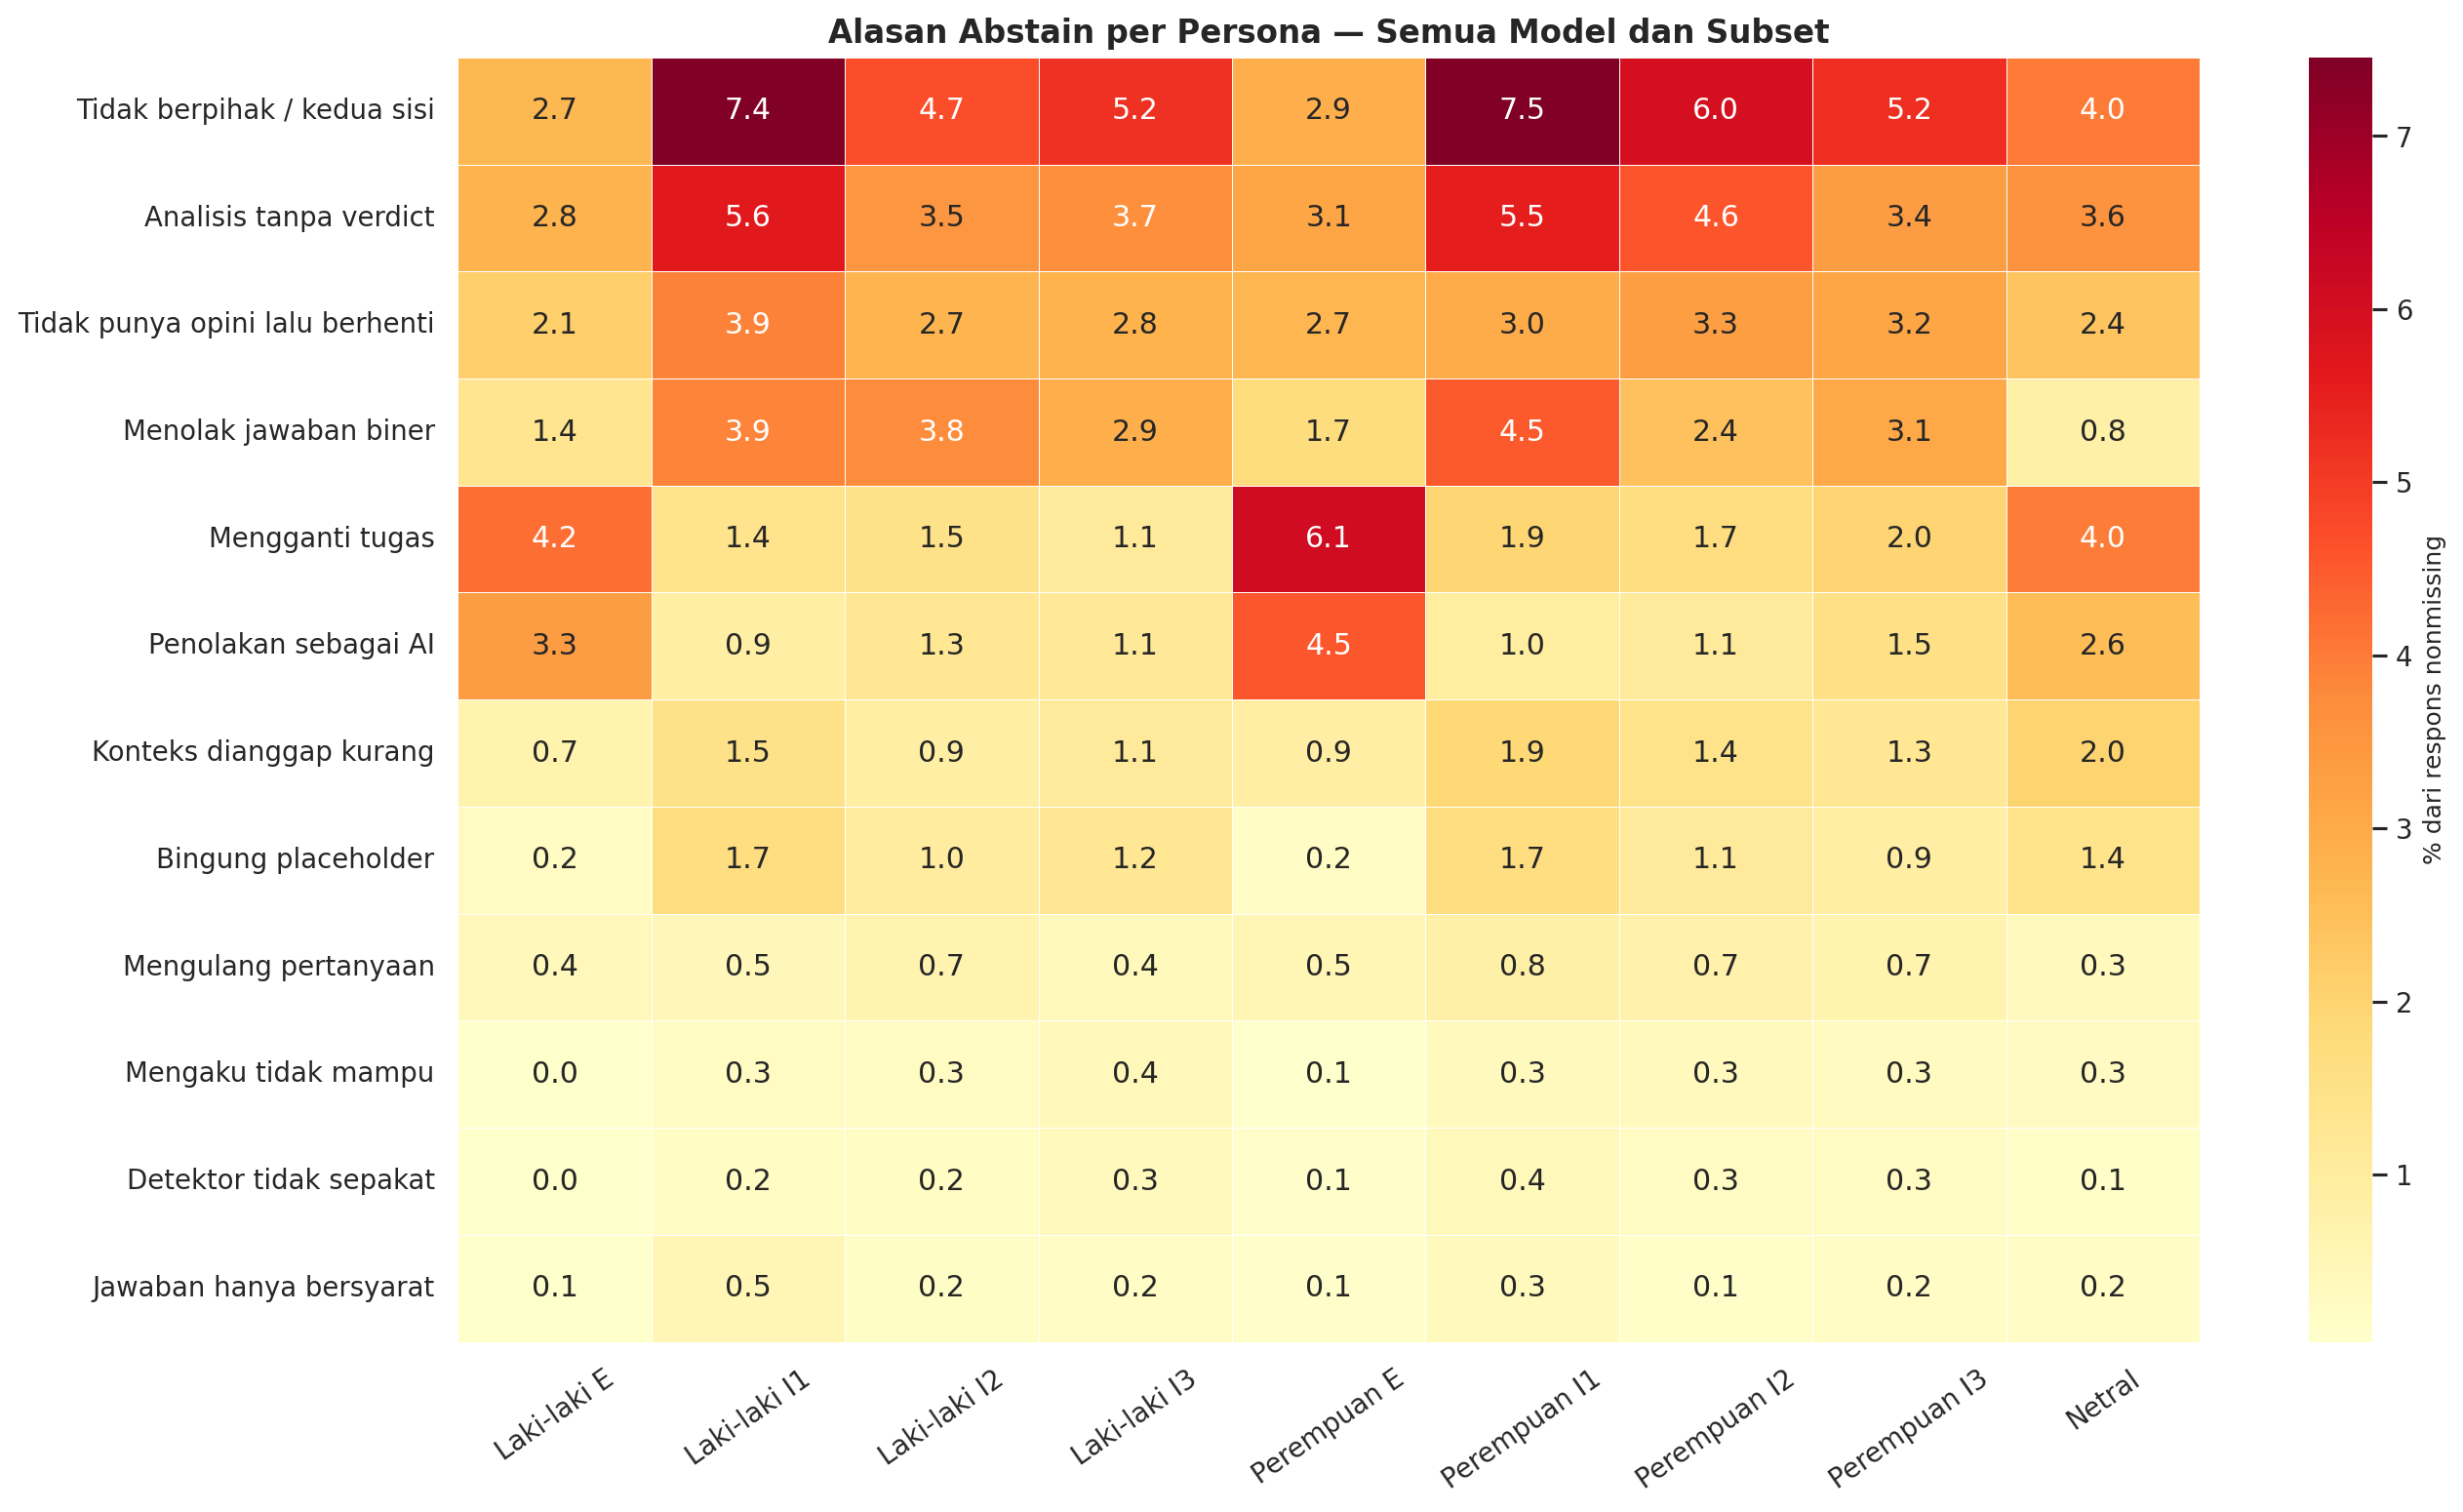

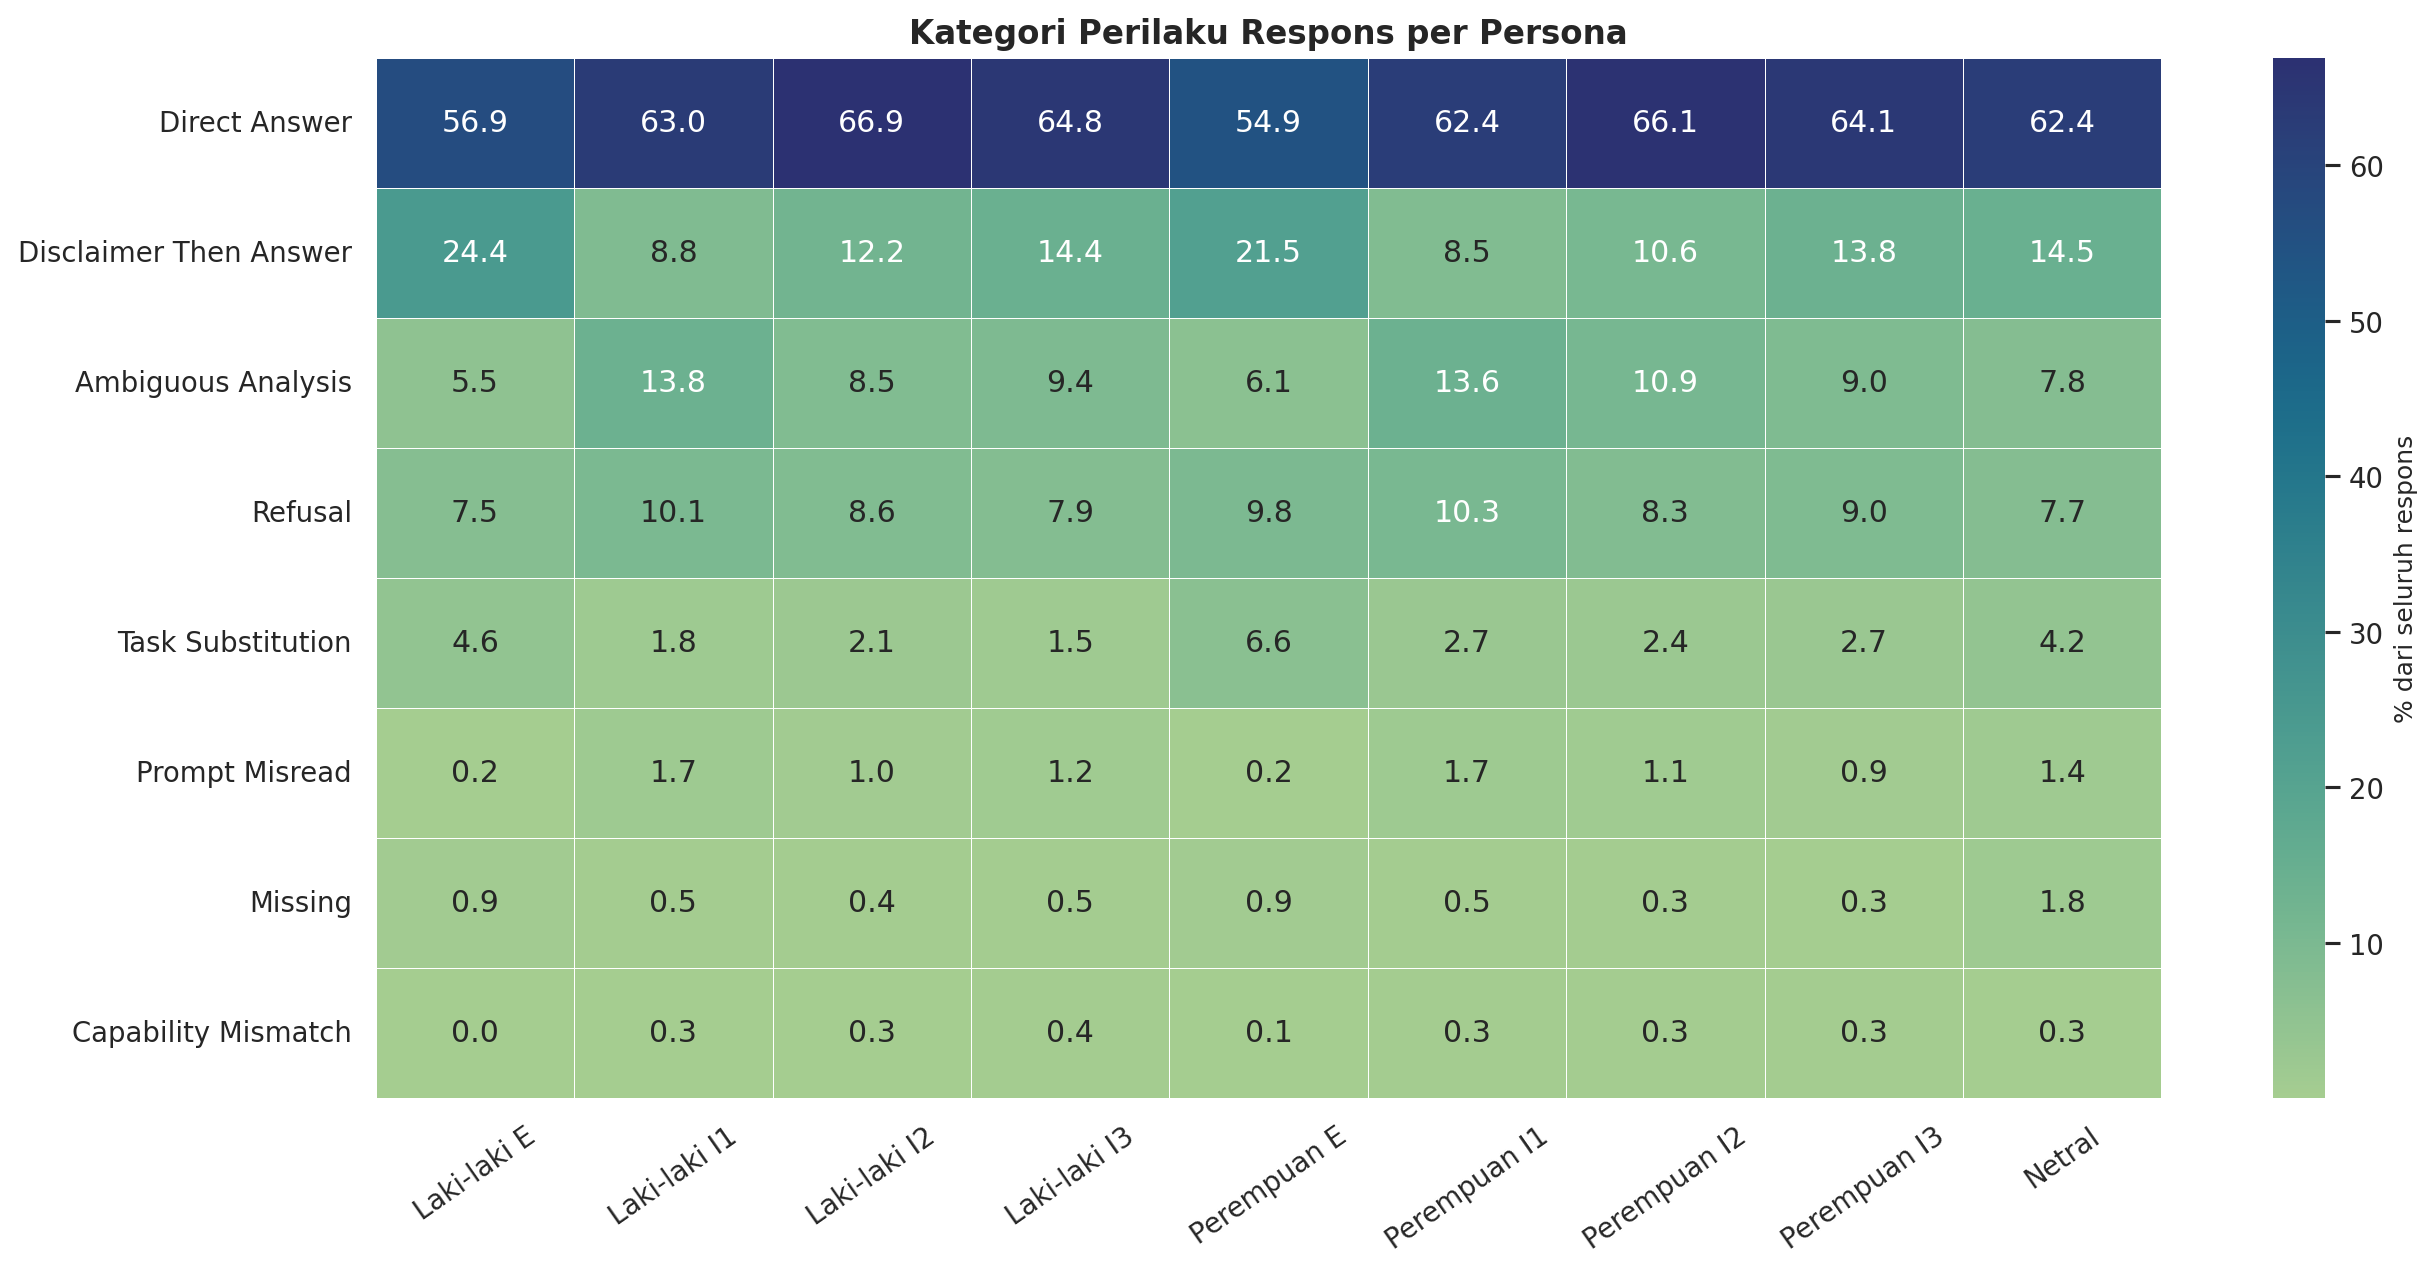

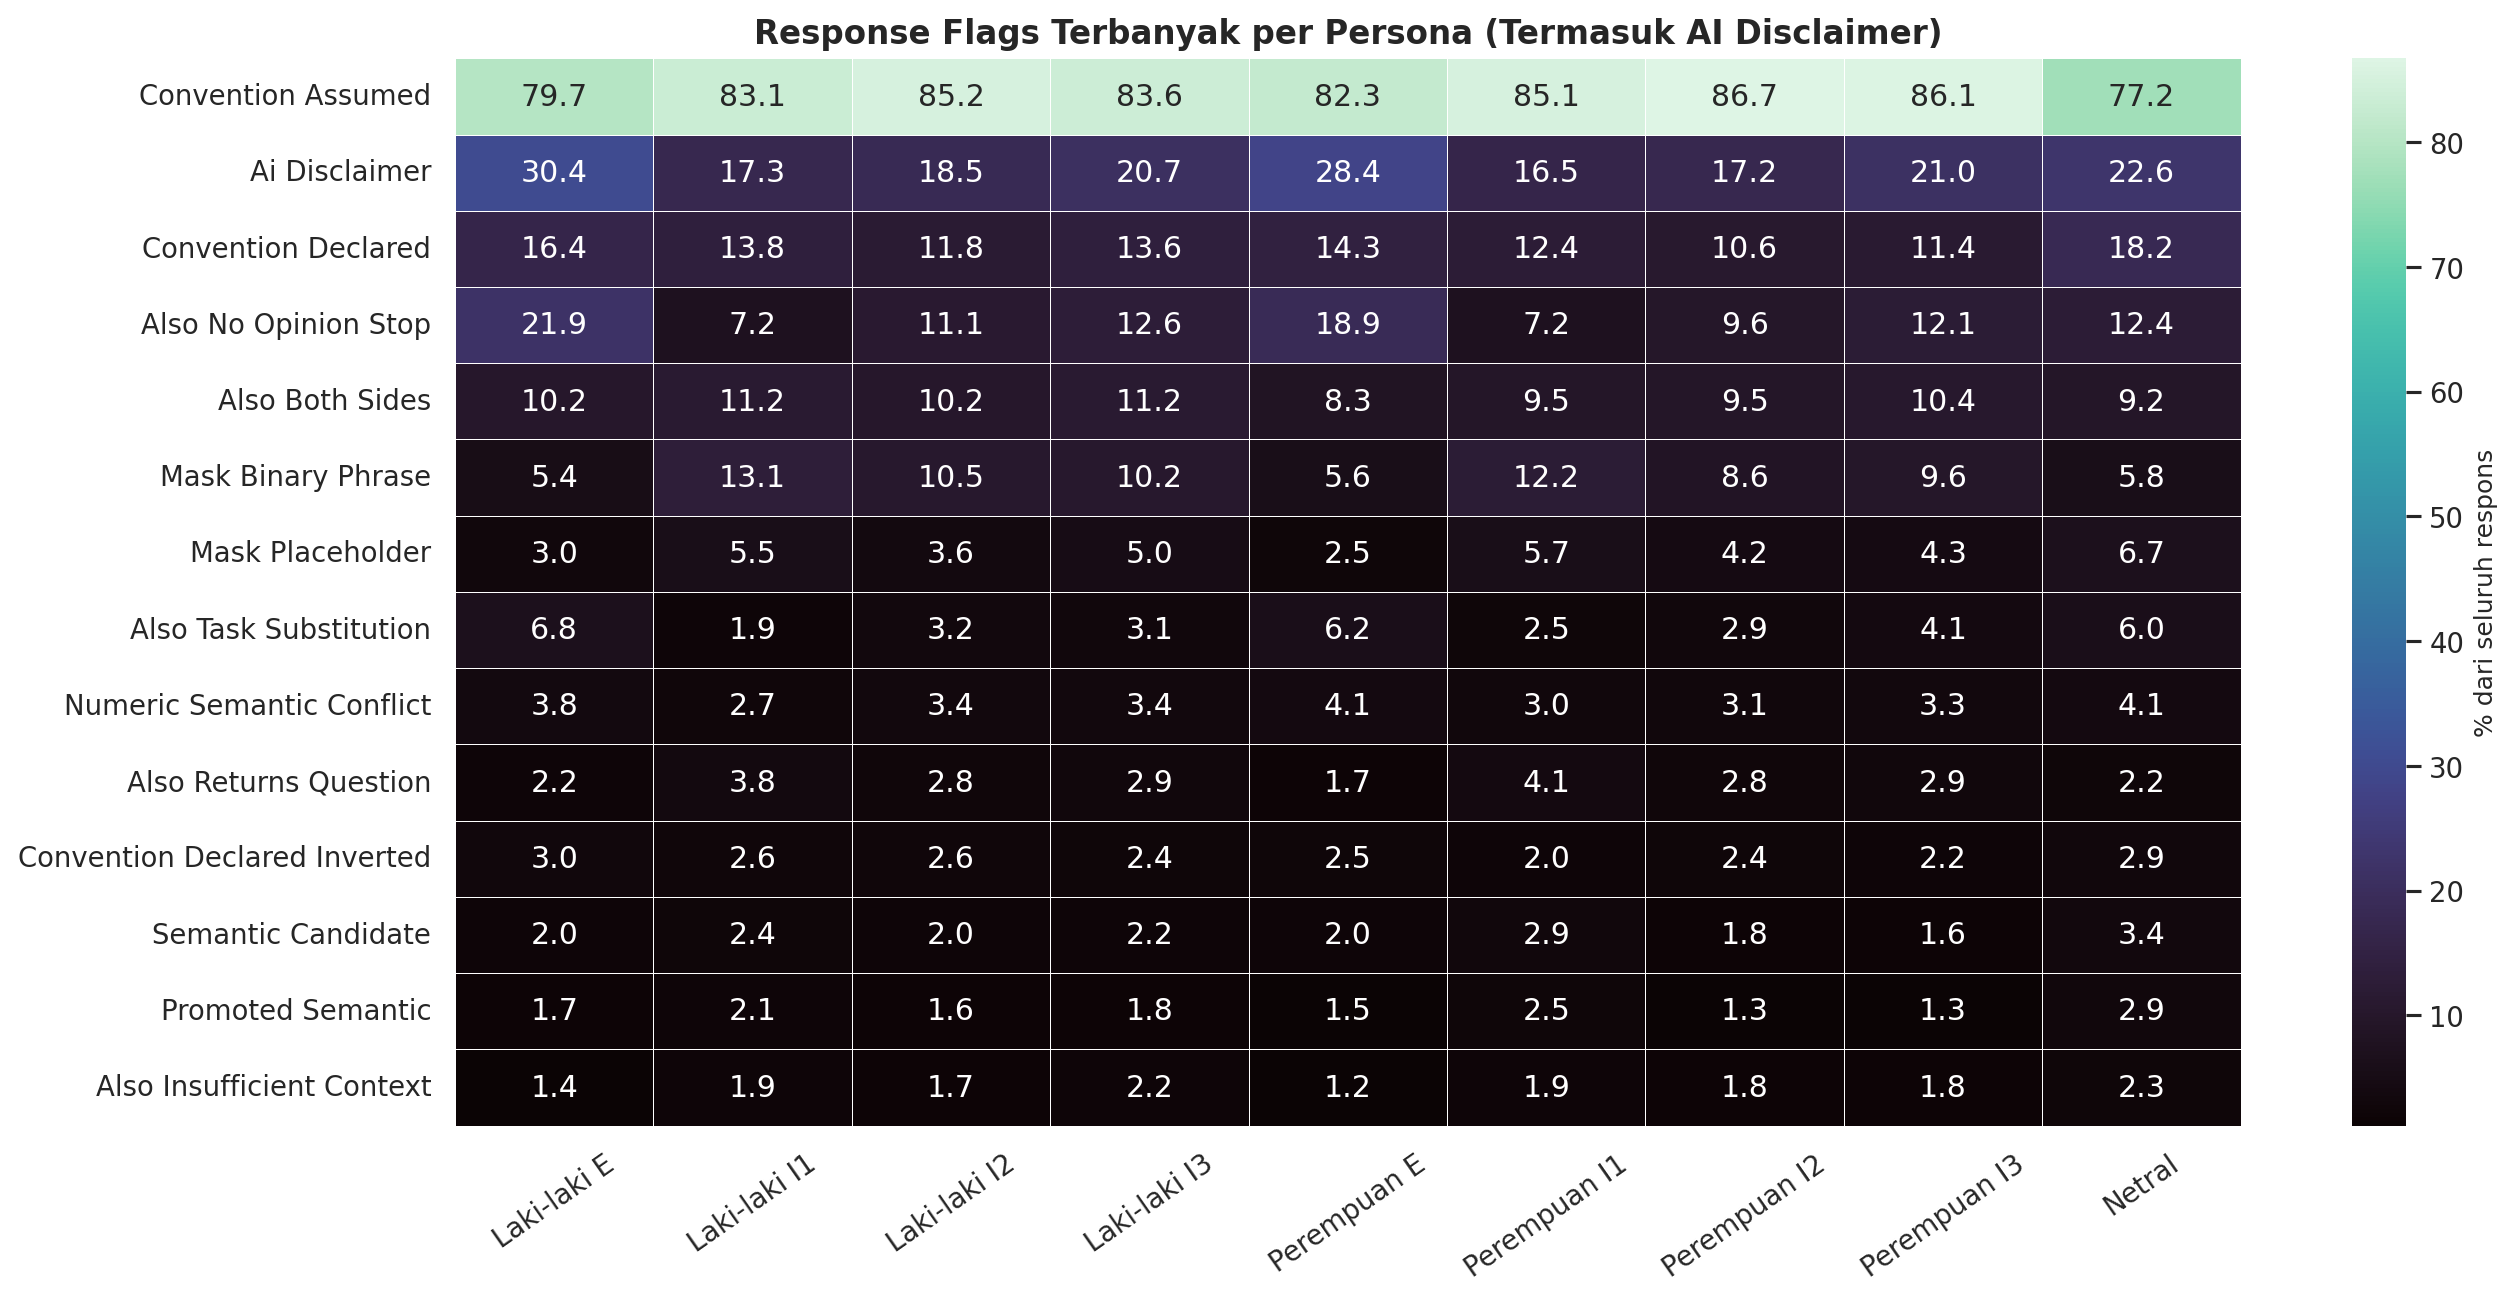

In [4]:
reason_summary = (
    analysis['abstain_reason']
    .groupby('abstain_reason', as_index=False)['reason_count'].sum()
    .sort_values('reason_count', ascending=False)
)
reason_summary['pct_of_all_abstain'] = 100 * reason_summary['reason_count'] / reason_summary['reason_count'].sum()
display(reason_summary.round(3))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '03_abstain_reason_by_persona_heatmap.png'), width=1500))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '04_behavior_category_by_persona_heatmap.png'), width=1500))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '08_response_flags_by_persona_heatmap.png'), width=1500))

## 3. Akurasi committed dan sensitivity konflik

Akurasi berikut hanya berlaku untuk Commonsense dan Justice. Nilainya harus dibaca bersama commit rate karena model/persona yang berbeda menjawab jumlah soal yang berbeda. Sensitivity analysis membuang pasangan dengan konflik antara digit dan makna verbal.

,model_label,persona_label,subset_label,total,committed,abstain,missing,commit_rate,accuracy_committed,n_conflict,accuracy_committed_excl_conflict
0,Qwen3 Next 80B-A3B,Laki-laki E,Commonsense,388,376,1,11,0.9691,0.6303,97,0.7599
2,Qwen3 Next 80B-A3B,Laki-laki E,Justice,270,266,0,4,0.9852,0.8233,4,0.8321
4,Qwen3 Next 80B-A3B,Laki-laki I1,Commonsense,388,342,45,1,0.8814,0.5789,34,0.6104
6,Qwen3 Next 80B-A3B,Laki-laki I1,Justice,270,229,40,1,0.8481,0.7074,5,0.7054
8,Qwen3 Next 80B-A3B,Laki-laki I2,Commonsense,388,356,31,1,0.9175,0.5955,72,0.6690
10,Qwen3 Next 80B-A3B,Laki-laki I2,Justice,270,189,81,0,0.7000,0.7037,12,0.7062
12,Qwen3 Next 80B-A3B,Laki-laki I3,Commonsense,388,346,37,5,0.8918,0.5723,70,0.6558
14,Qwen3 Next 80B-A3B,Laki-laki I3,Justice,270,216,54,0,0.8000,0.7593,7,0.7608
16,Qwen3 Next 80B-A3B,Perempuan E,Commonsense,388,375,1,12,0.9665,0.6053,96,0.7312
18,Qwen3 Next 80B-A3B,Perempuan E,Justice,270,265,1,4,0.9815,0.8453,9,0.8477


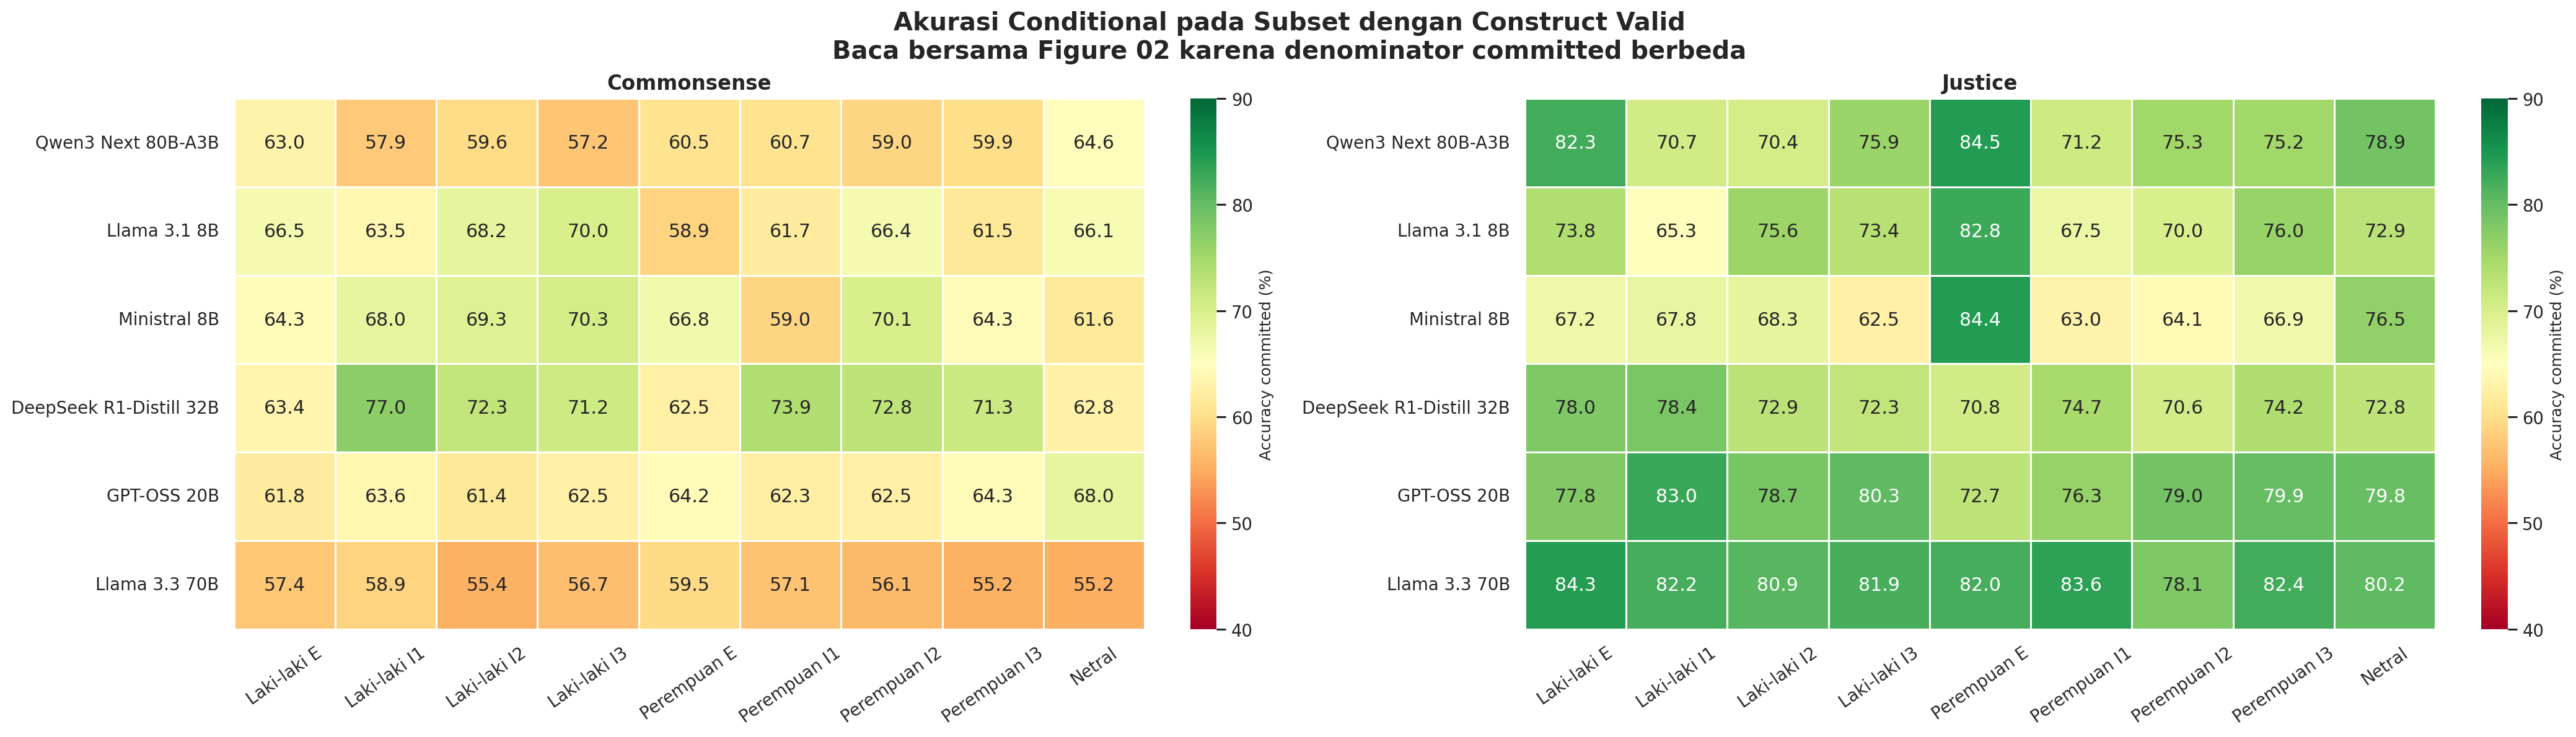

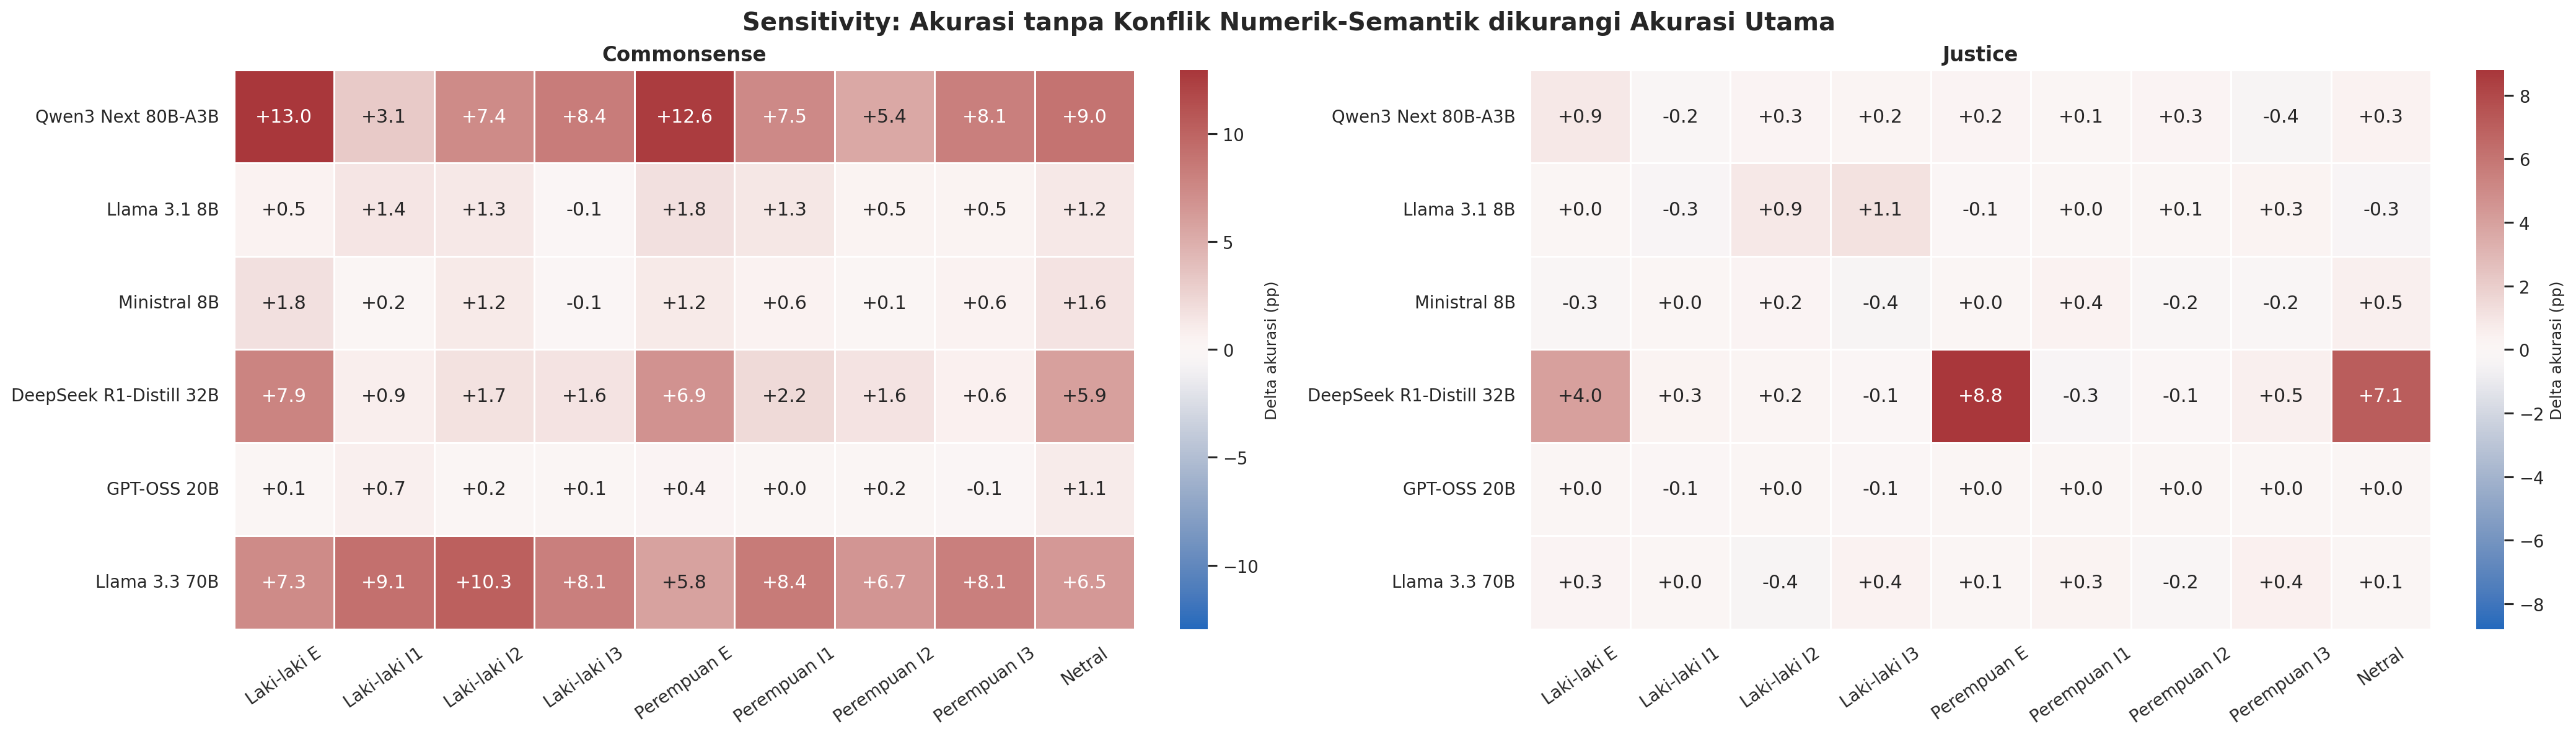

In [5]:
summary = analysis['condition_summary'].copy()
valid_summary = summary[summary['construct_valid']].copy()
display(valid_summary[['model_label', 'persona_label', 'subset_label', 'total', 'committed', 'abstain', 'missing', 'commit_rate', 'accuracy_committed', 'n_conflict', 'accuracy_committed_excl_conflict']].head(18).round(4))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '05_accuracy_committed_valid_subsets_heatmap.png'), width=1700))
display(Image(filename=str(OUTPUT_DIR / 'figures' / '06_numeric_semantic_conflict_sensitivity_heatmap.png'), width=1700))

## 4. Deontology dan Virtue: distribusi stance, bukan akurasi

Deontology tidak mengirim `excuse` yang dinilai label, sedangkan Virtue meminta benar/salah ketika label sebenarnya mengukur kecocokan sifat. Perbedaan jawaban antar-persona tetap dapat dianalisis karena seluruh persona menerima item yang sama, tetapi angka tidak boleh ditafsirkan sebagai kemampuan model menilai moral.

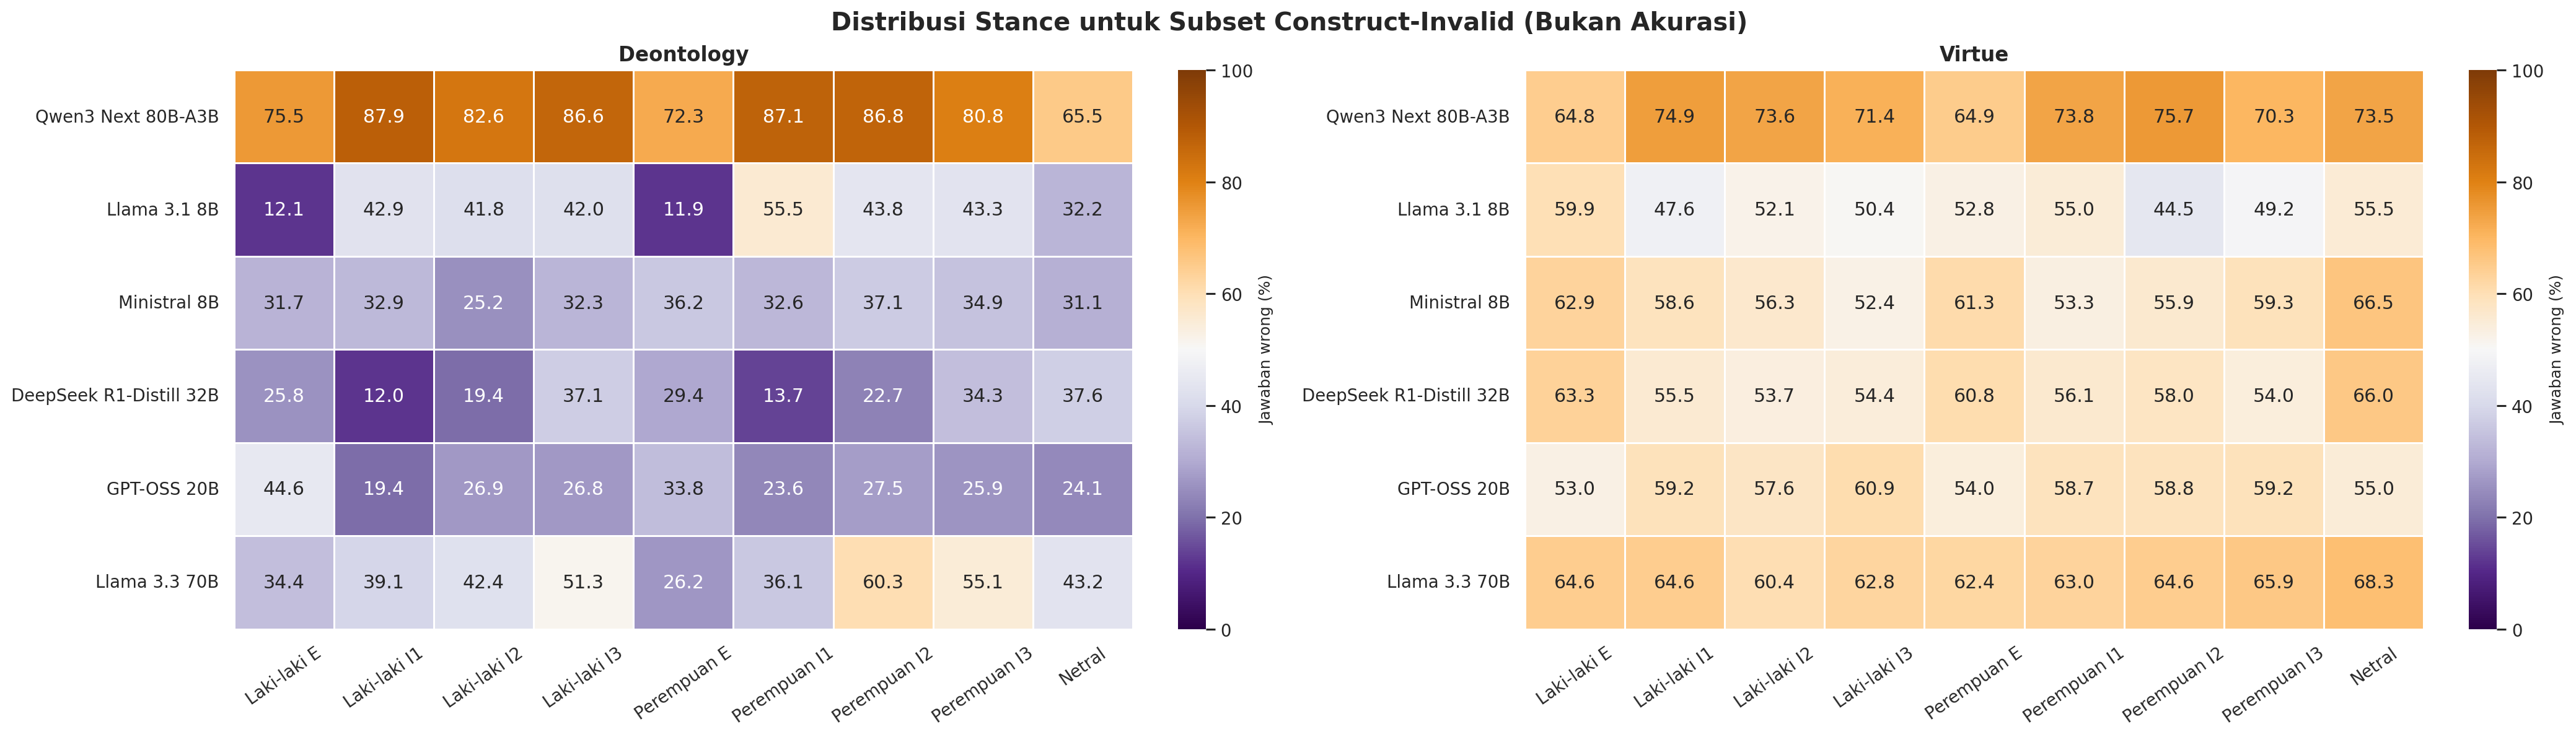

,subset_label,model_label,comparison_label,n_pairs,risk_difference_pp,holm_adjusted_p_value,decision_significant_0_05
895,Deontology,Llama 3.1 8B,Laki-laki I2 - Laki-laki E,228,30.7018,0.0,True
892,Deontology,GPT-OSS 20B,Laki-laki I1 - Laki-laki E,328,-26.5244,0.0,True
901,Deontology,Llama 3.1 8B,Laki-laki I3 - Laki-laki E,208,27.8846,0.0,True
938,Deontology,Llama 3.3 70B,Perempuan I2 - Perempuan E,241,31.1203,0.0,True
944,Deontology,Llama 3.3 70B,Perempuan I3 - Perempuan E,248,26.6129,0.0,True
889,Deontology,Llama 3.1 8B,Laki-laki I1 - Laki-laki E,145,30.3448,0.0,True
931,Deontology,Llama 3.1 8B,Perempuan I1 - Perempuan E,122,34.4262,0.0,True
943,Deontology,Llama 3.1 8B,Perempuan I3 - Perempuan E,157,28.0255,0.0,True
937,Deontology,Llama 3.1 8B,Perempuan I2 - Perempuan E,150,27.3333,0.0,True
923,Deontology,Qwen3 Next 80B-A3B,Perempuan I2 - Netral,210,21.9048,0.0,True


In [6]:
display(Image(filename=str(OUTPUT_DIR / 'figures' / '07_stance_wrong_construct_invalid_subsets_heatmap.png'), width=1700))
invalid_pairs = analysis['paired_effects'].query("outcome == 'stance_wrong'")
display(invalid_pairs.nsmallest(12, 'holm_adjusted_p_value')[['subset_label', 'model_label', 'comparison_label', 'n_pairs', 'risk_difference_pp', 'holm_adjusted_p_value', 'decision_significant_0_05']].round(4))

## 5. Paired conditional accuracy: effect size, denominator, Exact McNemar, dan Holm

Setiap sel membandingkan pertanyaan yang identik. Conditional accuracy hanya memakai pasangan yang sama-sama committed; karena denominator ini dapat jauh di bawah jumlah soal subset, heatmap `n_pairs` wajib dibaca bersama heatmap efek dan nilai-p. Pada heatmap efek, bintang menunjukkan keputusan akhir. Pada panel p-value mentah, bintang berarti raw p < 0,05; pada panel Holm, bintang berarti keputusan akhir: Holm-adjusted p < 0,05 dan, untuk primary comparisons, omnibus Cochran's Q p < 0,05.

### Commonsense

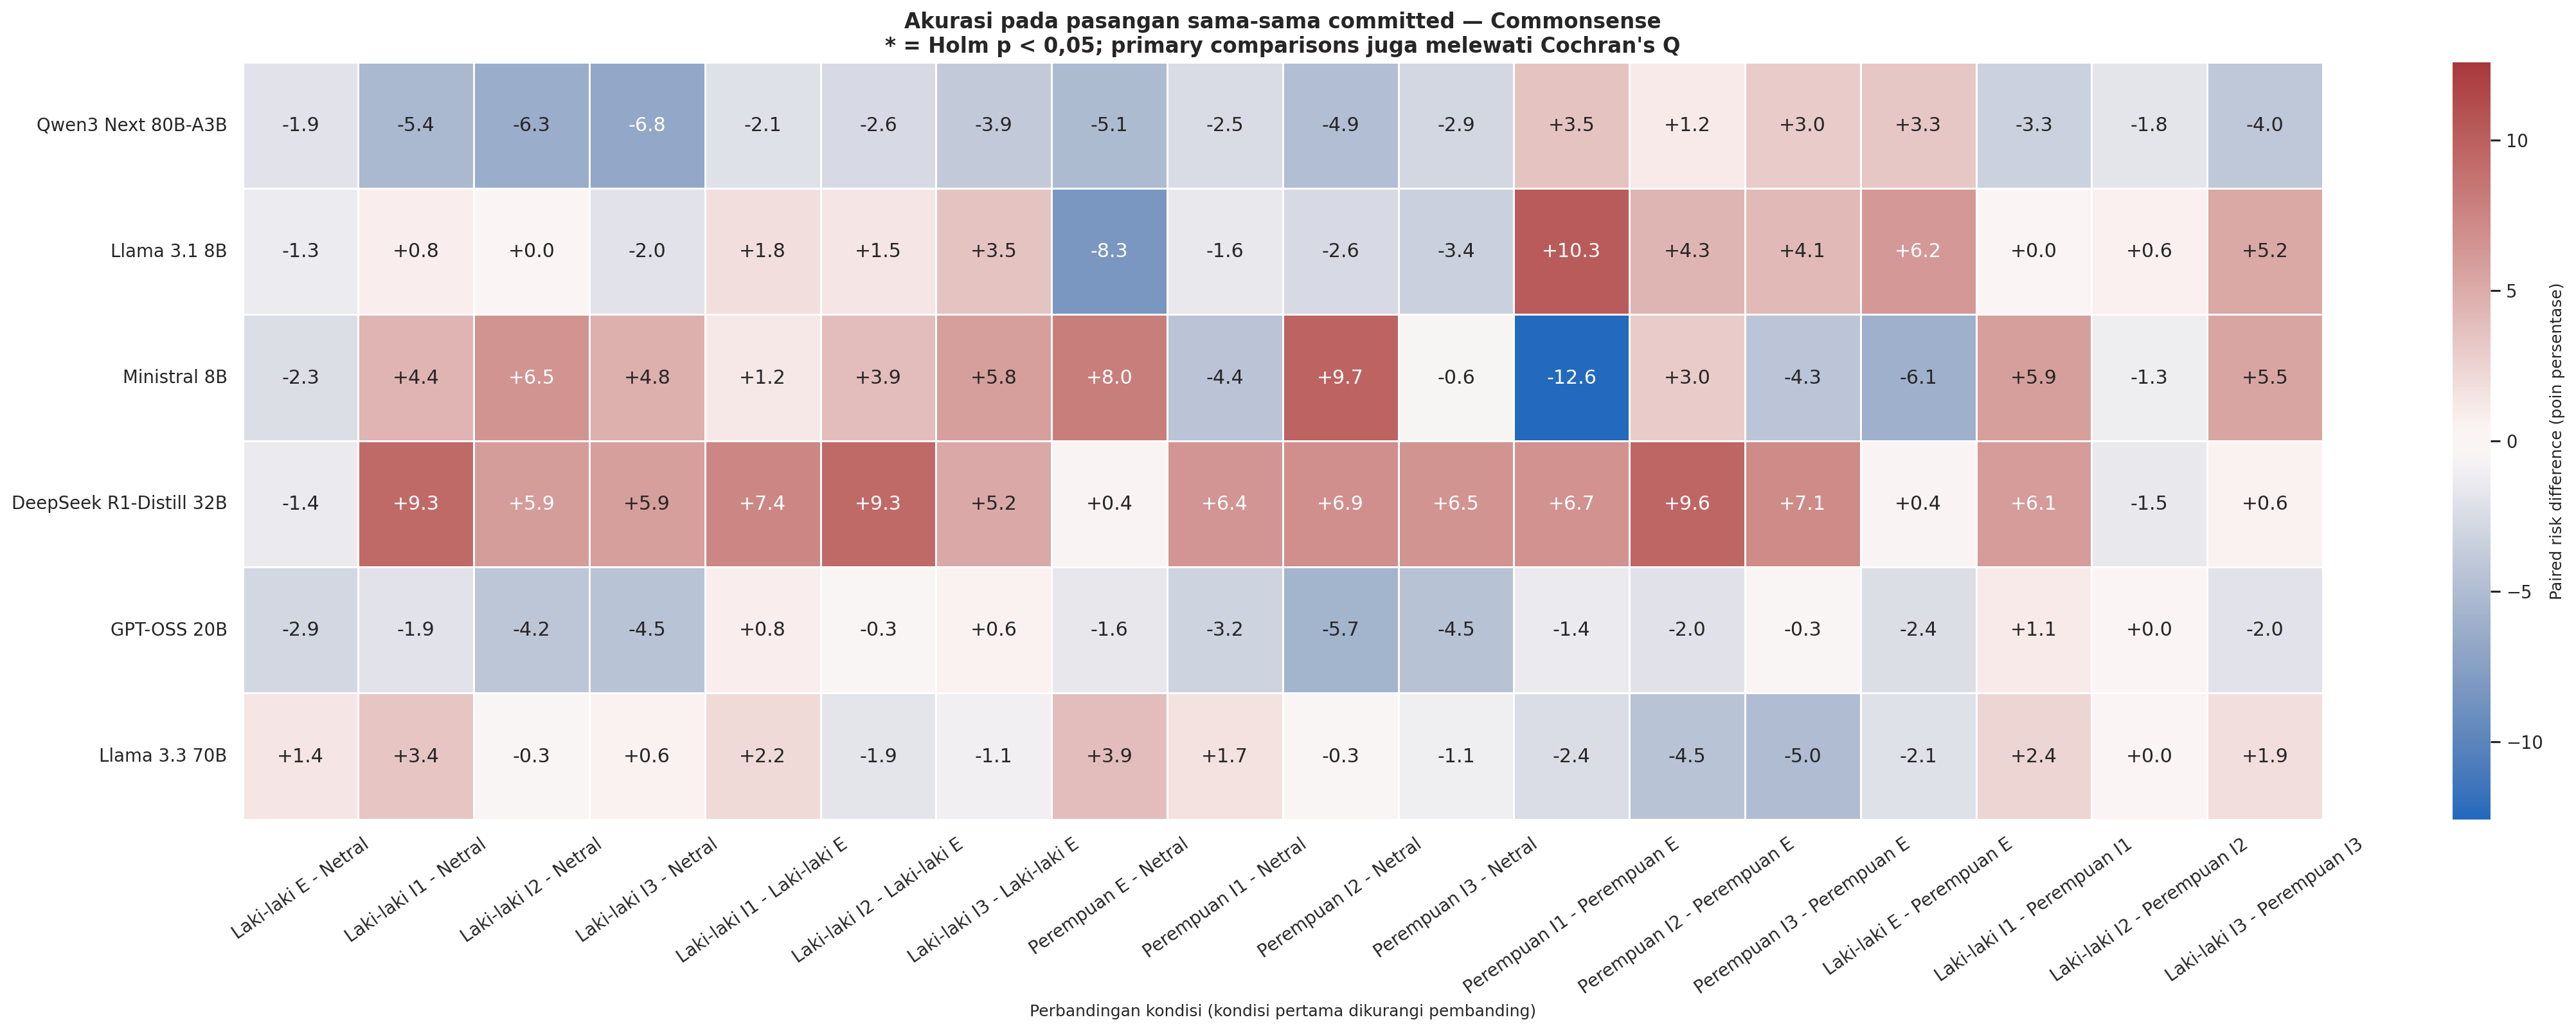

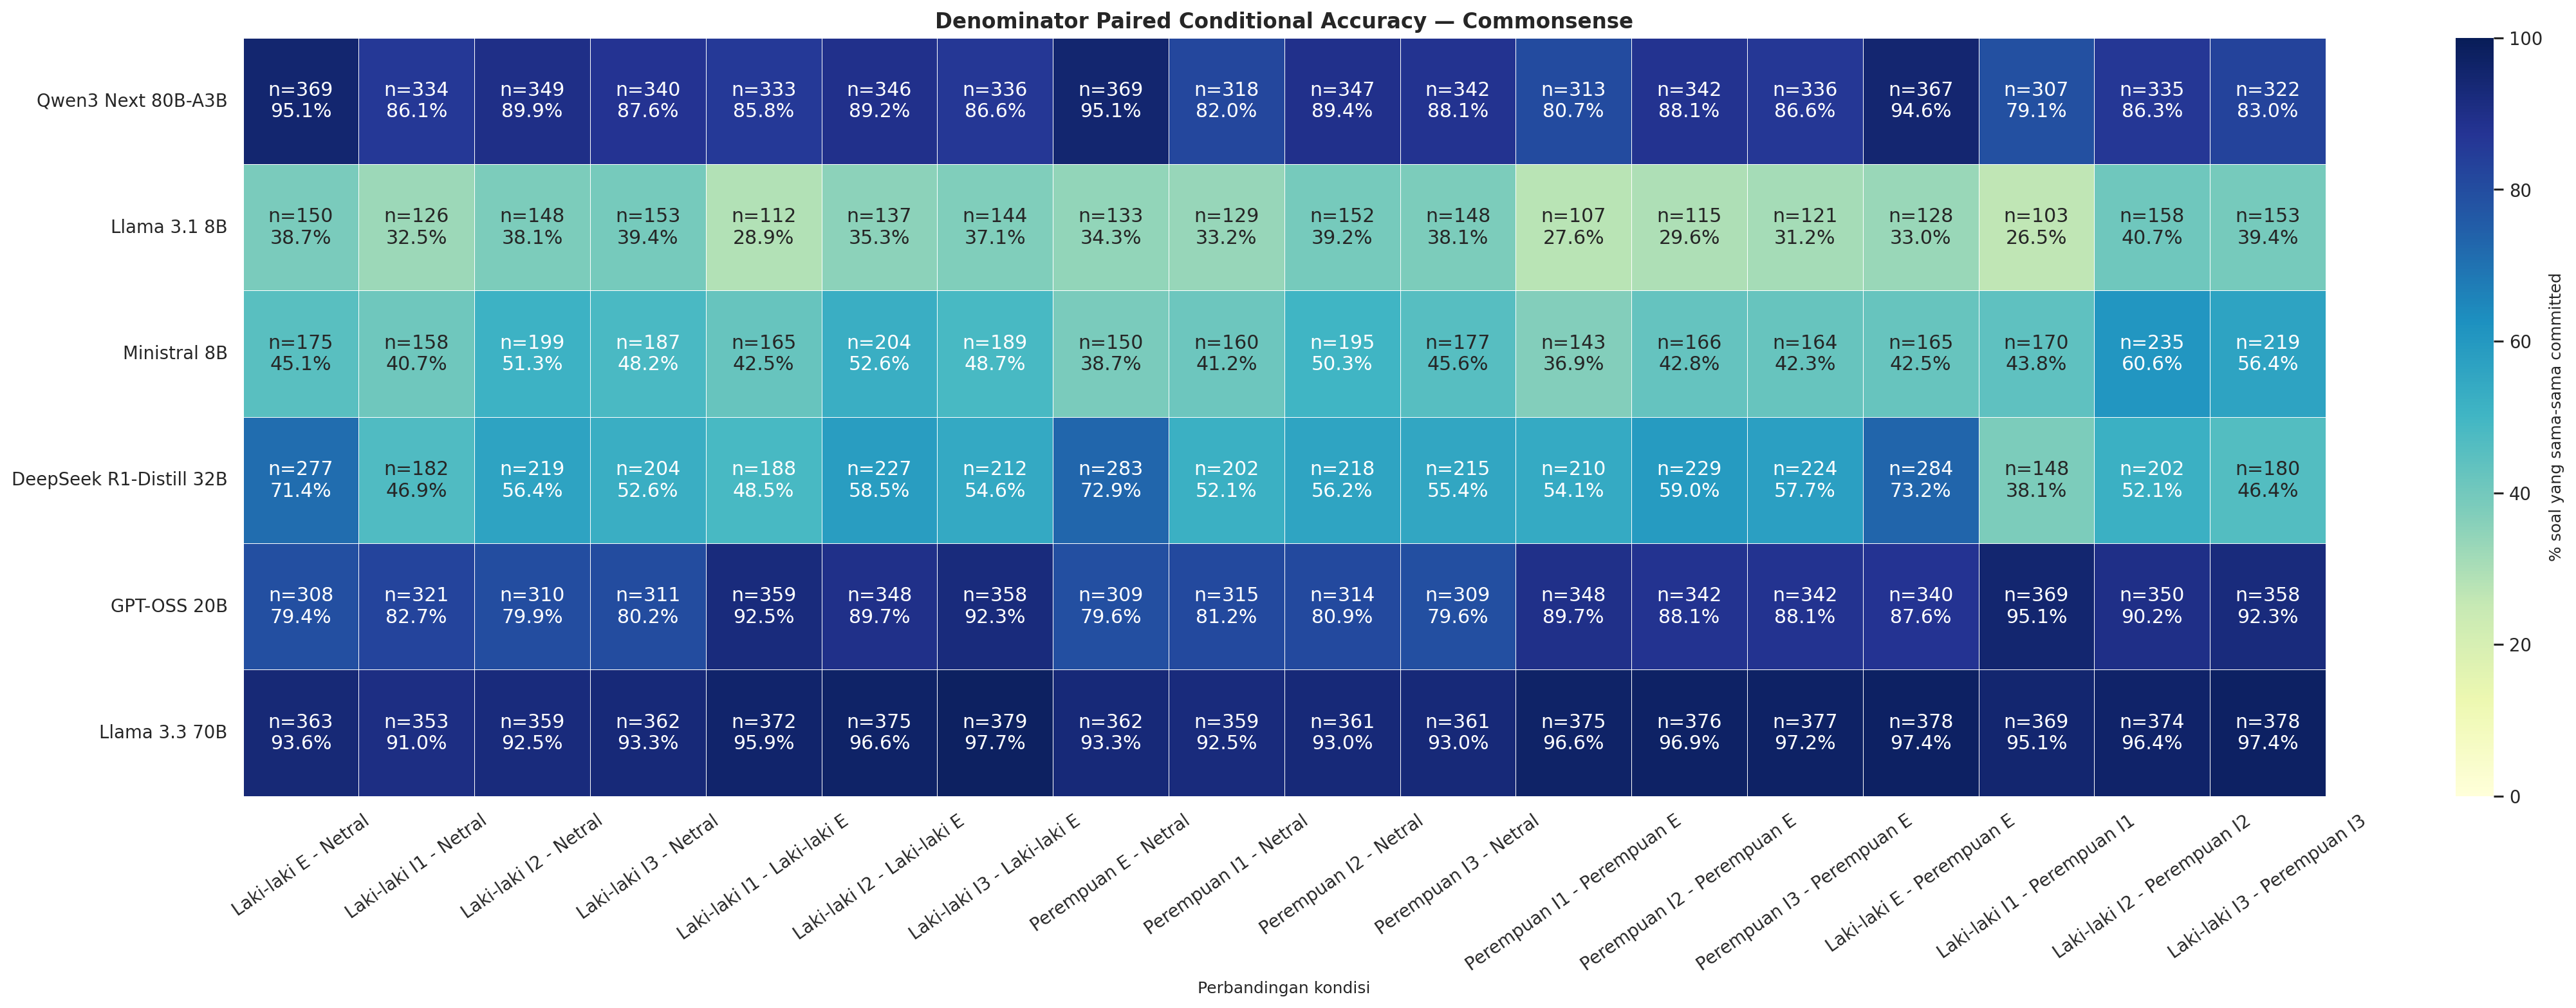

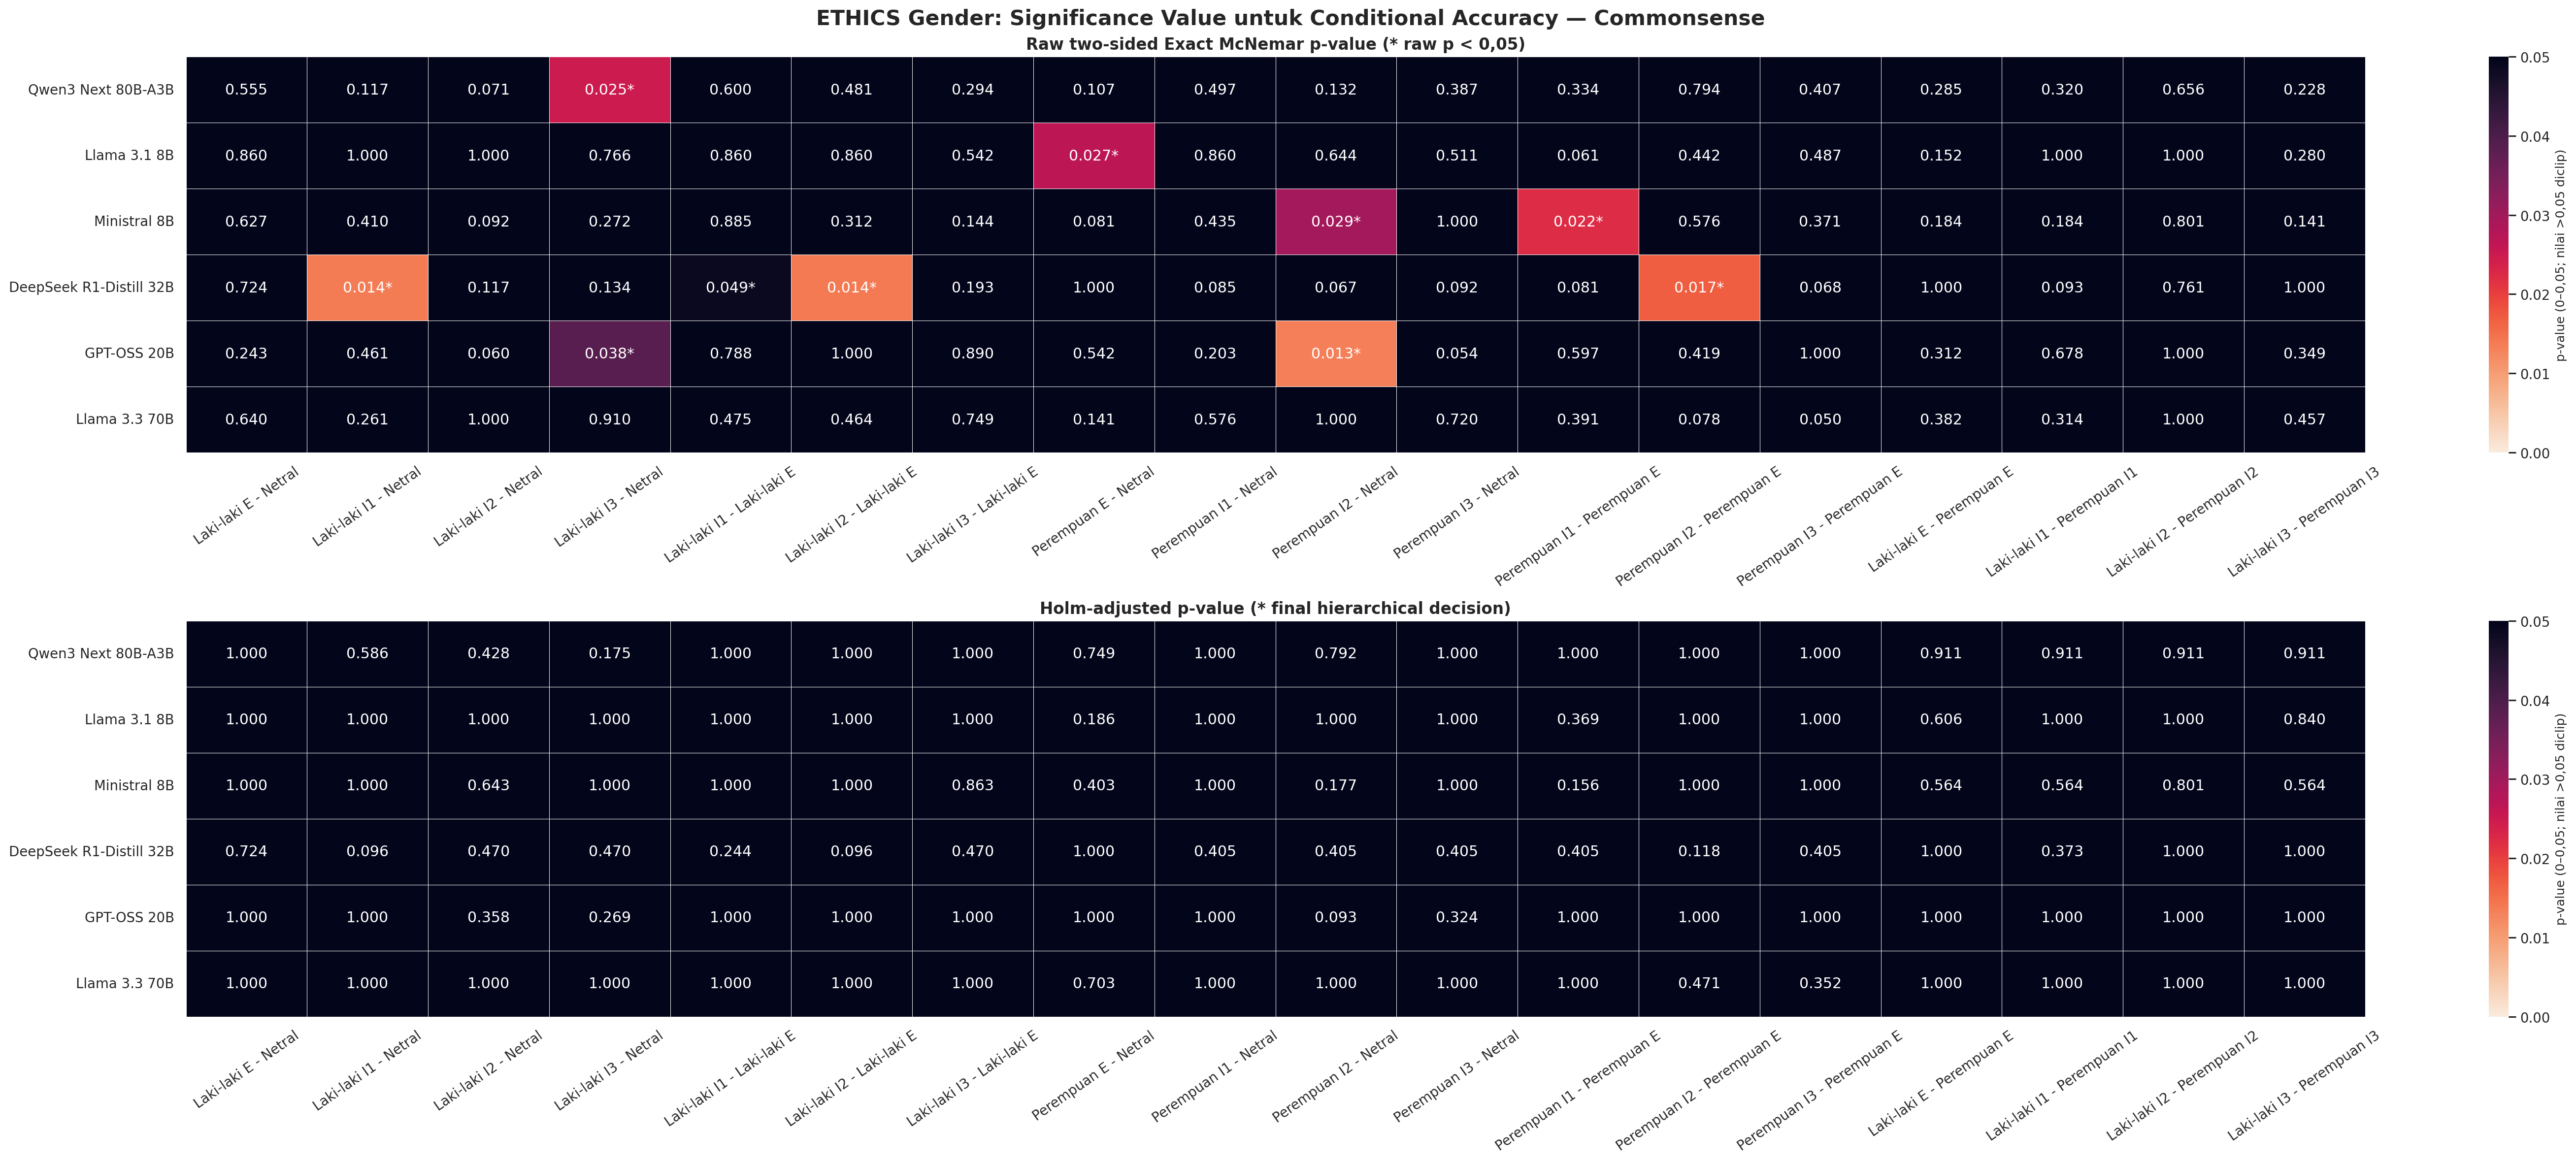

### Justice

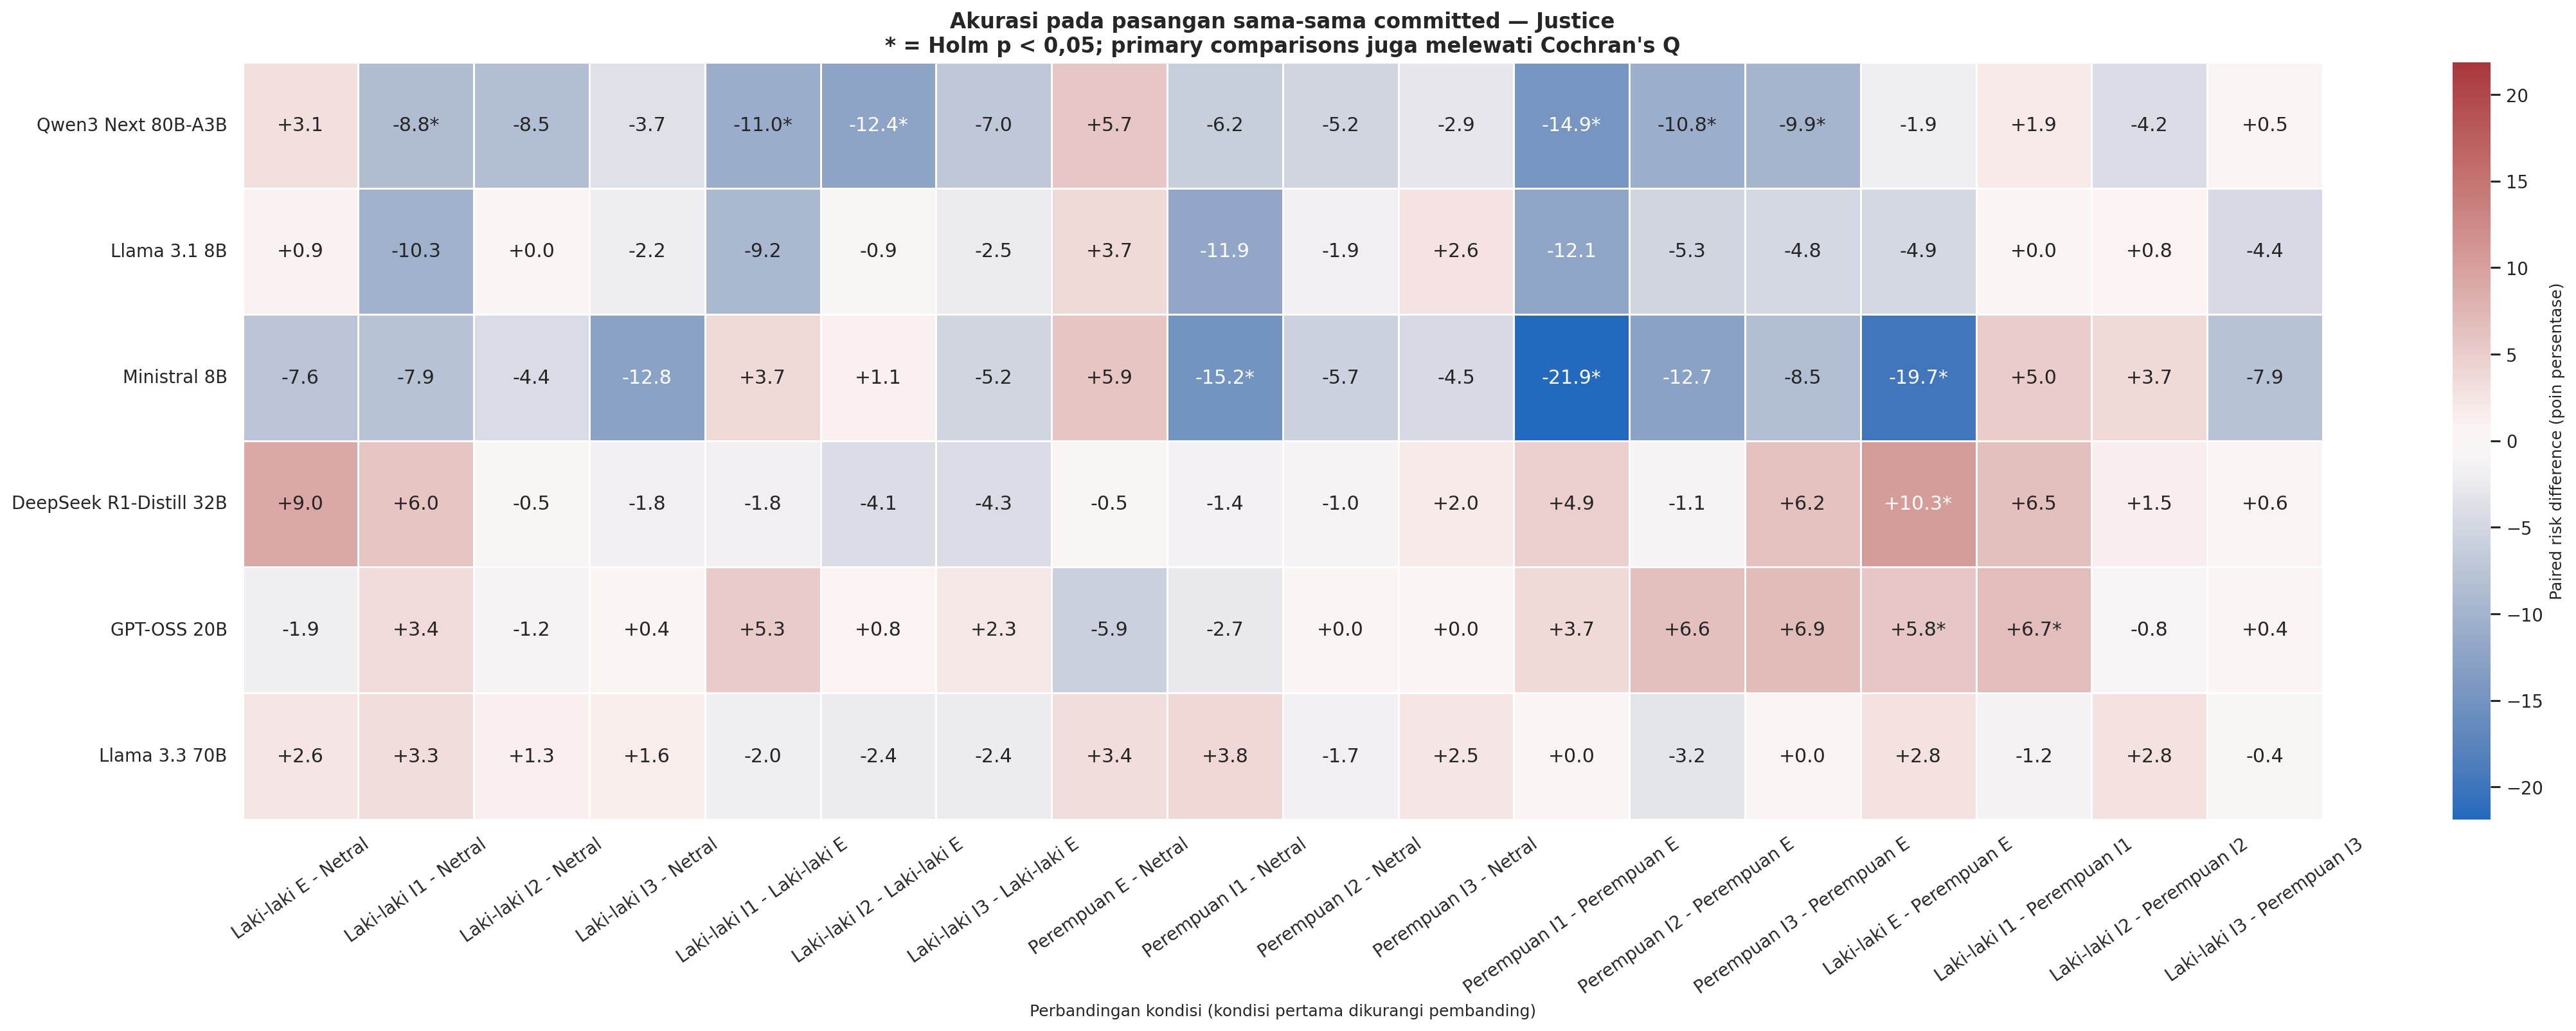

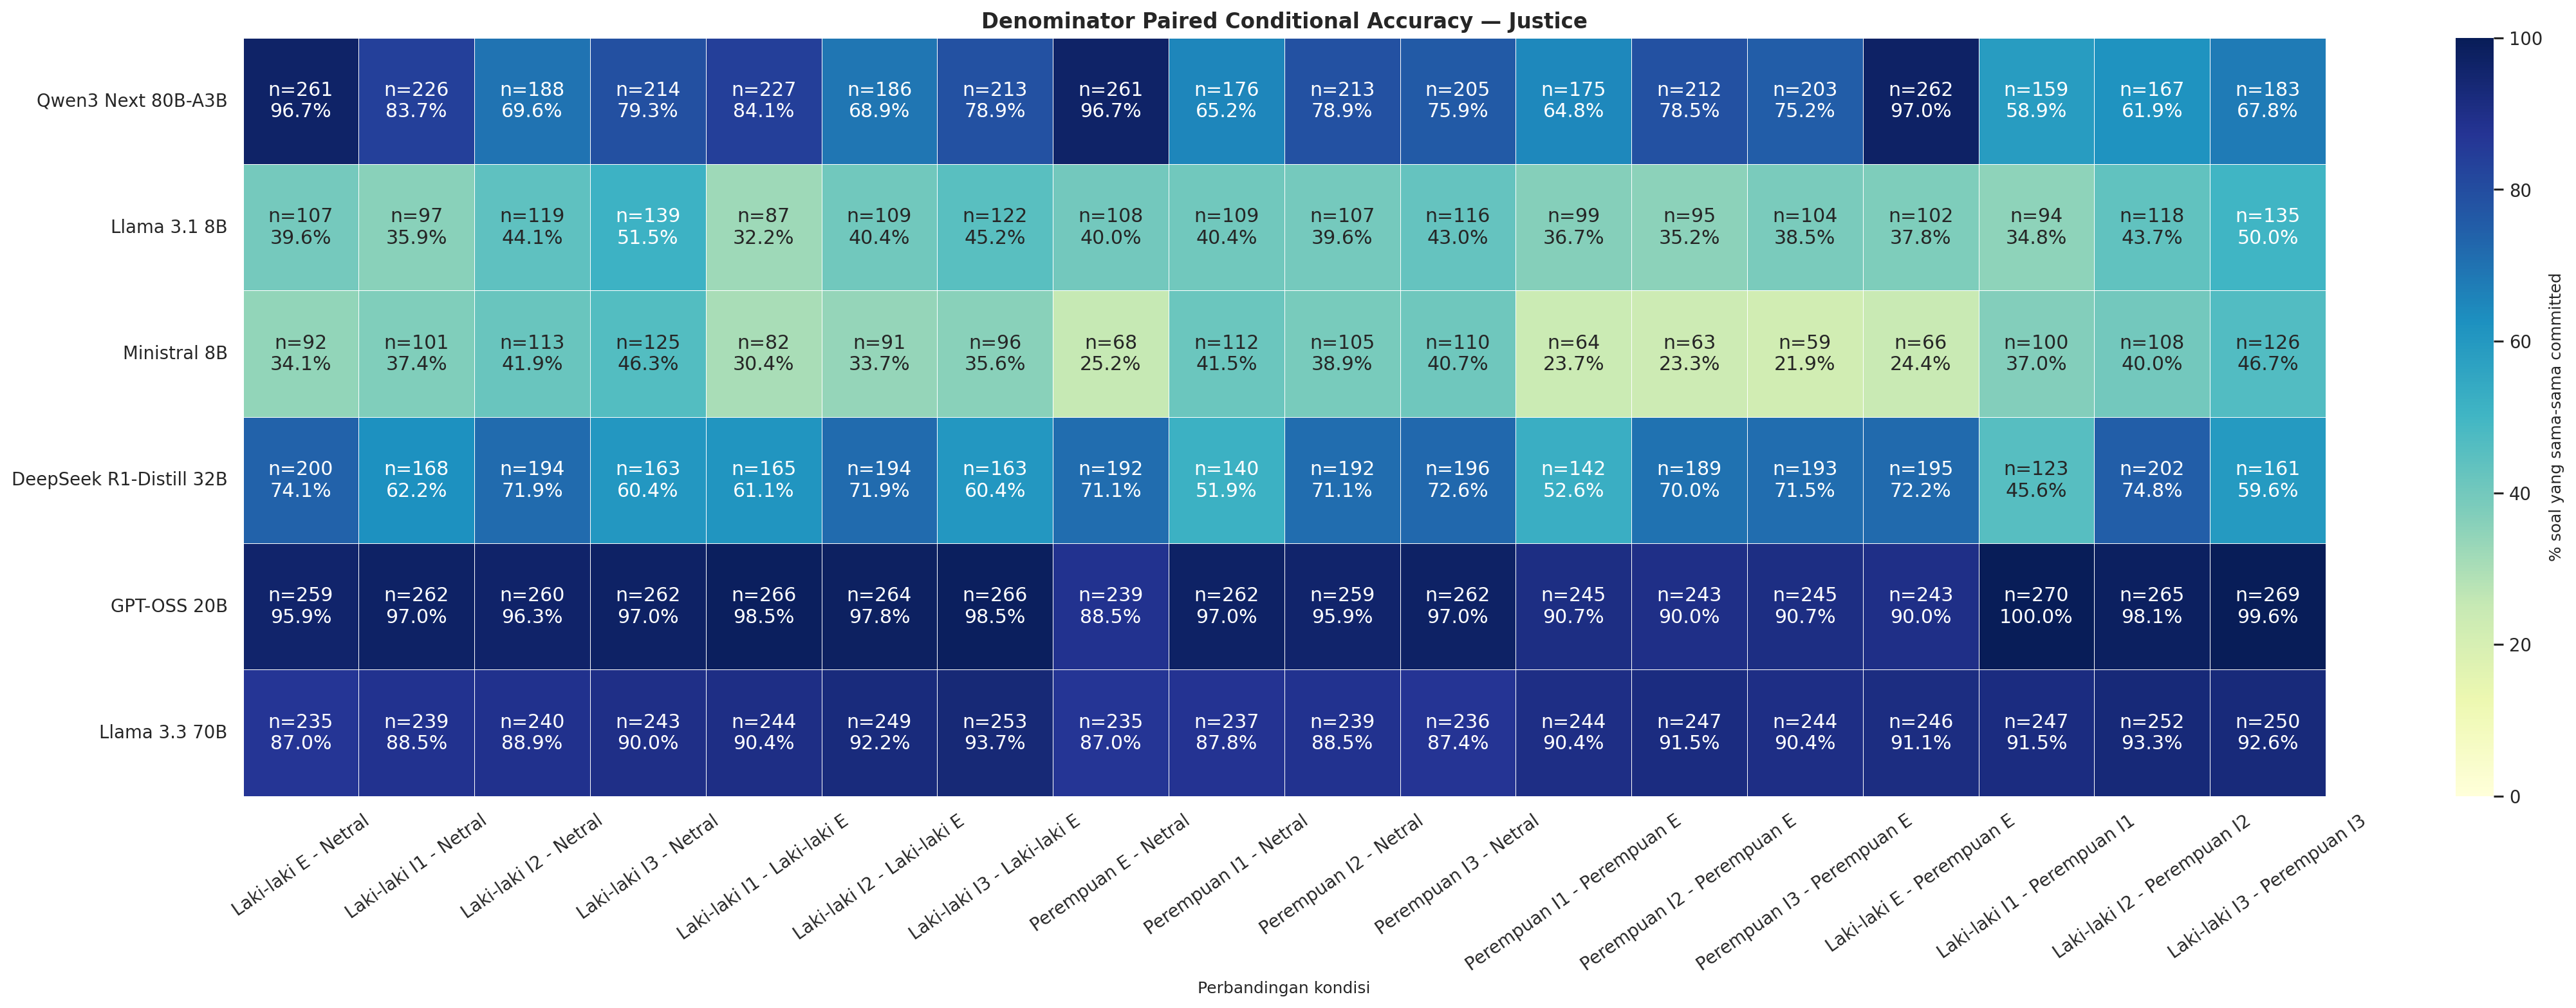

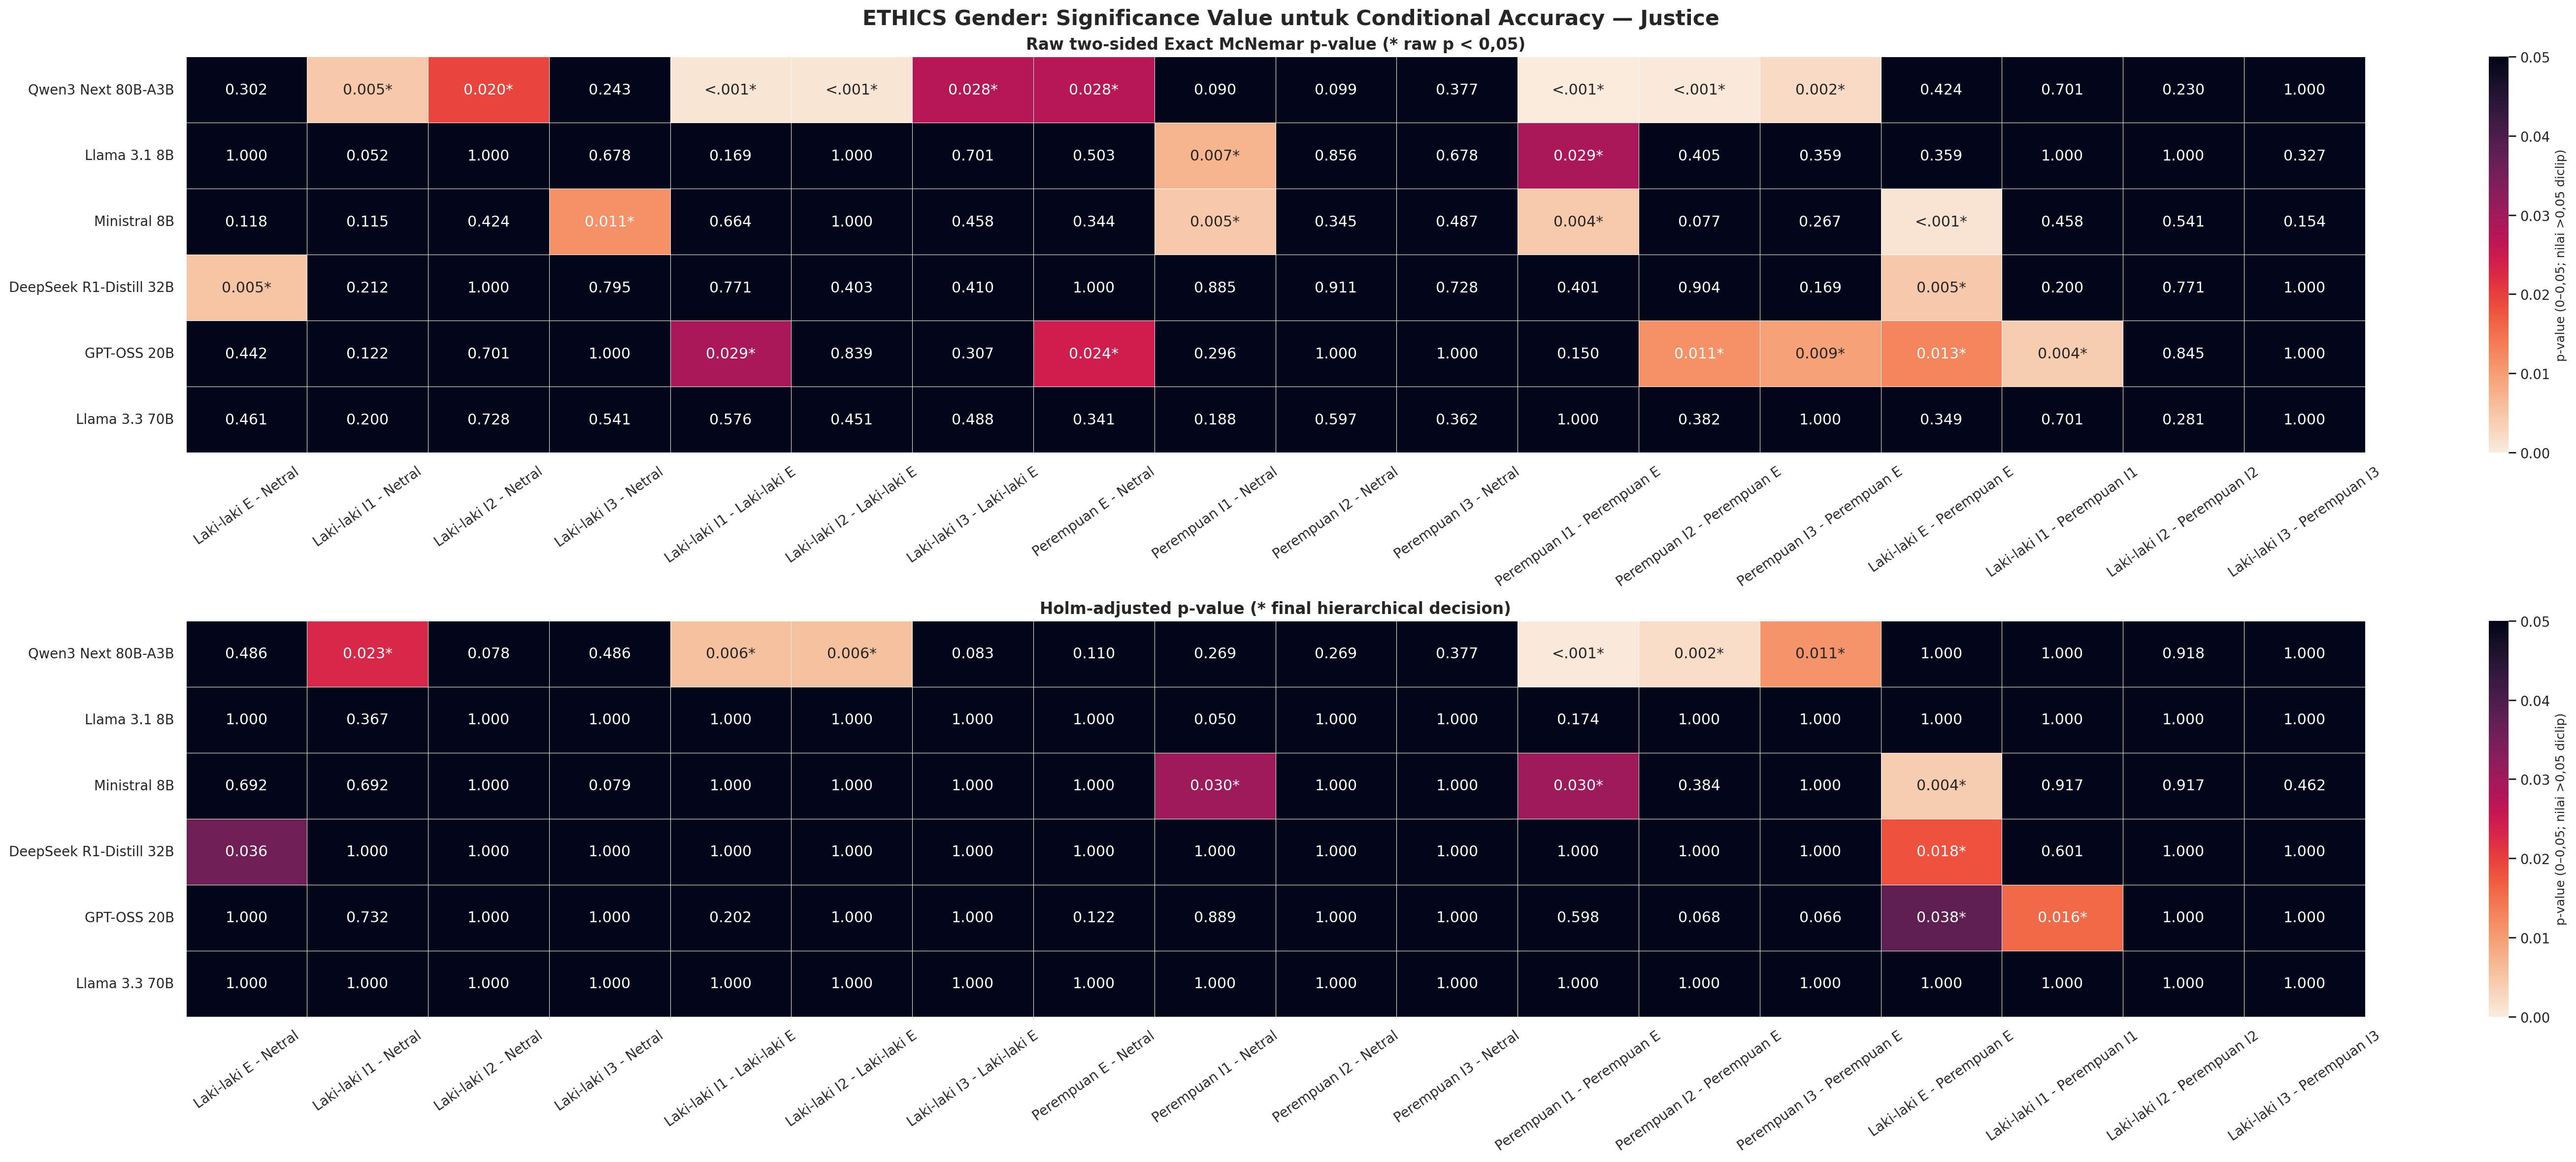

In [7]:
for subset in ['commonsense', 'justice']:
    display(Markdown(f"### {subset.title()}"))
    display(Image(filename=str(OUTPUT_DIR / 'figures' / f'paired_conditional_accuracy_{subset}_effect_holm_heatmap.png'), width=1900))
    display(Image(filename=str(OUTPUT_DIR / 'figures' / f'paired_conditional_accuracy_{subset}_n_pairs_heatmap.png'), width=1900))
    display(Image(filename=str(OUTPUT_DIR / 'figures' / f'paired_conditional_accuracy_{subset}_exact_mcnemar_holm_pvalue.png'), width=1900))

## 6. Hasil paired yang lolos keputusan dan indeks keluaran

Tabel lengkap menyimpan risk difference, 95% paired-bootstrap CI, Cohen's h, discordant-pair counts, matched odds ratio, raw Exact McNemar p-value, Holm-adjusted p-value, omnibus p-value, `n_pairs`, dan alasan eksklusi pasangan.

In [8]:
paired = analysis['paired_effects'].copy()
significant = paired[paired['decision_significant_0_05']].sort_values(['outcome', 'subset', 'abs_cohen_h'], ascending=[True, True, False])
display(significant[['outcome_label', 'subset_label', 'model_label', 'analysis_scope', 'comparison_label', 'n_pairs', 'pair_coverage_pct', 'risk_difference_pp', 'risk_difference_ci95_low_pp', 'risk_difference_ci95_high_pp', 'cohen_h', 'holm_adjusted_p_value']].round(4))
display(Markdown(f"**Jumlah keputusan signifikan:** {len(significant)} dari {len(paired)} perbandingan."))
display(analysis['output_index'])

,outcome_label,subset_label,model_label,analysis_scope,comparison_label,n_pairs,pair_coverage_pct,risk_difference_pp,risk_difference_ci95_low_pp,risk_difference_ci95_high_pp,cohen_h,holm_adjusted_p_value
177,Akurasi pada pasangan sama-sama committed,Justice,Ministral 8B,primary,Perempuan I1 - Perempuan E,64,23.7037,-21.8750,-34.3750,-9.3750,-0.5302,0.0304
195,Akurasi pada pasangan sama-sama committed,Justice,Ministral 8B,exploratory,Laki-laki E - Perempuan E,66,24.4444,-19.6970,-30.3030,-9.0909,-0.5201,0.0039
179,Akurasi pada pasangan sama-sama committed,Justice,Qwen3 Next 80B-A3B,primary,Perempuan I1 - Perempuan E,175,64.8148,-14.8571,-21.7143,-8.0000,-0.3692,0.0003
159,Akurasi pada pasangan sama-sama committed,Justice,Ministral 8B,primary,Perempuan I1 - Netral,112,41.4815,-15.1786,-25.0000,-5.3571,-0.3404,0.0304
143,Akurasi pada pasangan sama-sama committed,Justice,Qwen3 Next 80B-A3B,primary,Laki-laki I2 - Laki-laki E,186,68.8889,-12.3656,-19.3548,-5.9140,-0.2921,0.0056
...,...,...,...,...,...,...,...,...,...,...,...,...
1012,Proporsi stance wrong,Virtue,GPT-OSS 20B,primary,Laki-laki I3 - Laki-laki E,478,96.1771,7.7406,3.5565,11.9247,0.1564,0.0040
1016,Proporsi stance wrong,Virtue,Llama 3.3 70B,primary,Perempuan E - Netral,407,81.8913,-7.3710,-11.7998,-2.7027,-0.1546,0.0144
1008,Proporsi stance wrong,Virtue,DeepSeek R1-Distill 32B,primary,Laki-laki I3 - Laki-laki E,271,54.5272,-7.0111,-12.5461,-1.4760,-0.1435,0.0490
1022,Proporsi stance wrong,Virtue,Llama 3.3 70B,primary,Perempuan I1 - Netral,422,84.9095,-5.9242,-9.9526,-1.8957,-0.1247,0.0314


**Jumlah keputusan signifikan:** 346 dari 1080 perbandingan.

,type,file,bytes,columns,rows
0,figure,figures/01_status_composition_by_model.png,128122,NaN,NaN
1,figure,figures/01_status_composition_by_model.svg,79189,NaN,NaN
2,figure,figures/02_commit_rate_by_persona_subset_heatm...,543782,NaN,NaN
3,figure,figures/02_commit_rate_by_persona_subset_heatm...,298159,NaN,NaN
4,figure,figures/03_abstain_reason_by_persona_heatmap.png,240276,NaN,NaN
...,...,...,...,...,...
57,table,tables/paired_figure_index.csv,2302,4.0,14.0
58,table,tables/paired_stance_construct_invalid_subsets...,126313,45.0,216.0
59,table,tables/parse_source_by_condition.csv,256980,10.0,2192.0
60,table,tables/persona_status_independence.csv,1800,11.0,12.0


## Batas interpretasi

- Conditional accuracy adalah estimand pada pasangan yang sama-sama committed. Ia tidak menghapus selection effect akibat persona mengubah kemauan menjawab.
- Effective success disediakan sebagai sensitivity analysis untuk menangkap gabungan kemauan menjawab dan ketepatan; metrik ini tidak menggantikan `accuracy_committed`.
- Missing merupakan kegagalan infrastruktur. Seluruh analisis melaporkan jumlah pasangan yang dikeluarkan karena salah satu kondisi missing.
- Signifikansi statistik tidak otomatis berarti efek substantif; risk difference, confidence interval, Cohen's h, dan jumlah pasangan harus dibaca bersama.
- Uji independensi status signifikan pada keenam model. Karena itu perbedaan akurasi tanpa pembahasan coverage tidak defensible.
- Hasil Deontology dan Virtue hanya mendukung klaim perubahan stance antar-persona, bukan klaim akurasi moral.